<a href="https://colab.research.google.com/github/SrishtiSingh-code/2024UCS1685-CFG-visualizer-Srishti-Singh/blob/main/AudioDeepfake_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

%pip install -q librosa scikit-learn transformers accelerate soundfile pandas scipy matplotlib

In [ ]:
!pip -q install datasets soundfile

In [ ]:
from datasets import load_dataset_builder

name = "Bisher/ASVspoof_2019_LA"
builder = load_dataset_builder(name)

print("Dataset:", name)
print("Splits:", builder.info.splits)
print("Features:", builder.info.features)

README.md:   0%|          | 0.00/784 [00:00<?, ?B/s]

Dataset: Bisher/ASVspoof_2019_LA
Splits: {'train': SplitInfo(name='train', num_bytes=1515101755.52, num_examples=25380), 'validation': SplitInfo(name='validation', num_bytes=1462206958.528, num_examples=24844), 'test': SplitInfo(name='test', num_bytes=4334147022.707, num_examples=71237)}
Features: {'speaker_id': Value('string'), 'audio_file_name': Value('string'), 'audio': Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None), 'system_id': Value('string'), 'key': ClassLabel(names=['bonafide', 'spoof'])}


In [ ]:
from datasets import load_dataset

name = "Bisher/ASVspoof_2019_LA"

ds = load_dataset(
    name,
    split="train[:3]"
)

print(ds)
print("\nFirst sample:")
print(ds[0].keys())

for key, value in ds[0].items():
    if key != "audio":
        print(key, ":", value)

print("\nAudio information:")
print("Sampling rate:", ds[0]["audio"]["sampling_rate"])
print("Audio array shape:", ds[0]["audio"]["array"].shape)

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.59GB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.58GB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.38GB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25380 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/24844 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/71237 [00:00<?, ? examples/s]

Dataset({
    features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
    num_rows: 3
})

First sample:
dict_keys(['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'])
speaker_id : LA_0079
audio_file_name : LA_T_1138215
system_id : -
key : 0

Audio information:
Sampling rate: 16000
Audio array shape: (55329,)


In [ ]:
print("Columns:", ds.column_names)

for i, sample in enumerate(ds):
    print(f"\nSample {i + 1}")
    print("Filename:", sample["audio_file_name"])
    print("System ID:", sample["system_id"])
    print("Label:", sample["key"])
    print("Sampling rate:", sample["audio"]["sampling_rate"])
    print("Audio shape:", sample["audio"]["array"].shape)

Columns: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key']

Sample 1
Filename: LA_T_1138215
System ID: -
Label: 0
Sampling rate: 16000
Audio shape: (55329,)

Sample 2
Filename: LA_T_1271820
System ID: -
Label: 0
Sampling rate: 16000
Audio shape: (70323,)

Sample 3
Filename: LA_T_1272637
System ID: -
Label: 0
Sampling rate: 16000
Audio shape: (46392,)


In [ ]:

print("Label values in loaded samples:")

for i, sample in enumerate(ds):
    print(
        f"Sample {i+1}: "
        f"filename={sample['audio_file_name']}, "
        f"key={sample['key']}, "
        f"system_id={sample['system_id']}"
    )

print("\nLabel feature information:")
print(ds.features["key"])


Label values in loaded samples:
Sample 1: filename=LA_T_1138215, key=0, system_id=-
Sample 2: filename=LA_T_1271820, key=0, system_id=-
Sample 3: filename=LA_T_1272637, key=0, system_id=-

Label feature information:
ClassLabel(names=['bonafide', 'spoof'])


In [ ]:

!pip -q install librosa


In [ ]:

import numpy as np
import librosa

def extract_features(audio, sr=16000):
    audio = np.asarray(audio, dtype=np.float32)

    # 20 MFCC coefficients
    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=20, n_fft=512, hop_length=160
    )

    # Delta MFCC
    delta = librosa.feature.delta(mfcc)

    # Spectral contrast
    contrast = librosa.feature.spectral_contrast(
        y=audio, sr=sr, n_fft=512, hop_length=160
    )

    # Mean and standard deviation pooling
    features = np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1),
        delta.mean(axis=1),
        delta.std(axis=1),
        contrast.mean(axis=1),
        contrast.std(axis=1)
    ])

    return features

# Test on the first already-loaded audio sample
sample = ds[0]
x = extract_features(
    sample["audio"]["array"],
    sr=sample["audio"]["sampling_rate"]
)

print("Feature vector shape:", x.shape)
print("Label:", sample["key"])
print("Feature extraction successful!")


Feature vector shape: (94,)
Label: 0
Feature extraction successful!


In [ ]:

from collections import Counter

labels = [int(sample["key"]) for sample in ds]

print("Total loaded samples:", len(ds))
print("Label counts:", Counter(labels))
print("Label names:", ds.features["key"].names)


Total loaded samples: 3
Label counts: Counter({0: 3})
Label names: ['bonafide', 'spoof']


In [ ]:

from datasets import load_dataset

stream_ds = load_dataset(
    "Bisher/ASVspoof_2019_LA",
    split="train",
    streaming=True
)

print("Streaming dataset ready.")

for i, sample in enumerate(stream_ds):
    print(
        "Sample:", i + 1,
        "| Label:", sample["key"],
        "| Filename:", sample["audio_file_name"]
    )

    if i == 9:
        break


Streaming dataset ready.
Sample: 1 | Label: 0 | Filename: LA_T_1138215
Sample: 2 | Label: 0 | Filename: LA_T_1271820
Sample: 3 | Label: 0 | Filename: LA_T_1272637
Sample: 4 | Label: 0 | Filename: LA_T_1276960
Sample: 5 | Label: 0 | Filename: LA_T_1341447
Sample: 6 | Label: 0 | Filename: LA_T_1363611
Sample: 7 | Label: 0 | Filename: LA_T_1596451
Sample: 8 | Label: 0 | Filename: LA_T_1608170
Sample: 9 | Label: 0 | Filename: LA_T_1684951
Sample: 10 | Label: 0 | Filename: LA_T_1699801


In [ ]:

import numpy as np
from collections import Counter

audio_samples = []
max_per_class = 10

for sample in stream_ds:
    label = int(sample["key"])

    # Keep at most 10 samples of each class
    if Counter(s["label"] for s in audio_samples)[label] >= max_per_class:
        continue

    audio_samples.append({
        "audio": sample["audio"]["array"],
        "sr": sample["audio"]["sampling_rate"],
        "label": label,
        "filename": sample["audio_file_name"]
    })

    counts = Counter(s["label"] for s in audio_samples)
    print("Collected:", counts)

    if counts.get(0, 0) >= max_per_class and counts.get(1, 0) >= max_per_class:
        break

print("\nFinal counts:", Counter(s["label"] for s in audio_samples))


Collected: Counter({0: 1})
Collected: Counter({0: 2})
Collected: Counter({0: 3})
Collected: Counter({0: 4})
Collected: Counter({0: 5})
Collected: Counter({0: 6})
Collected: Counter({0: 7})
Collected: Counter({0: 8})
Collected: Counter({0: 9})
Collected: Counter({0: 10})
Collected: Counter({0: 10, 1: 1})
Collected: Counter({0: 10, 1: 2})
Collected: Counter({0: 10, 1: 3})
Collected: Counter({0: 10, 1: 4})
Collected: Counter({0: 10, 1: 5})
Collected: Counter({0: 10, 1: 6})
Collected: Counter({0: 10, 1: 7})
Collected: Counter({0: 10, 1: 8})
Collected: Counter({0: 10, 1: 9})
Collected: Counter({0: 10, 1: 10})

Final counts: Counter({0: 10, 1: 10})


In [ ]:

# ============================================
# AUDIO DEEPFAKE DETECTION: SMALL PROTOTYPE
# MFCC + Delta MFCC + Spectral Contrast
# ============================================

!pip -q install librosa scikit-learn

import numpy as np
import librosa
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Verify collected data
print("Total audio samples:", len(audio_samples))
print("Label counts:", Counter(s["label"] for s in audio_samples))
print("Labels: 0 = bonafide, 1 = spoof")


# 2. Extract acoustic features
def extract_features(audio, sr=16000):
    audio = np.asarray(audio, dtype=np.float32)

    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=20,
        n_fft=512, hop_length=160
    )

    delta = librosa.feature.delta(mfcc)

    contrast = librosa.feature.spectral_contrast(
        y=audio, sr=sr,
        n_fft=512, hop_length=160
    )

    return np.concatenate([
        mfcc.mean(axis=1),
        mfcc.std(axis=1),
        delta.mean(axis=1),
        delta.std(axis=1),
        contrast.mean(axis=1),
        contrast.std(axis=1)
    ])


X = []
y = []

for i, sample in enumerate(audio_samples):
    features = extract_features(
        sample["audio"], sample["sr"]
    )
    X.append(features)
    y.append(sample["label"])

X = np.asarray(X)
y = np.asarray(y)

print("\nFeature matrix shape:", X.shape)
print("Labels shape:", y.shape)
print("Feature extraction completed!")


# 3. Split into train and test sets
# This is only a tiny pipeline check, NOT final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Test samples:", len(X_test))


# 4. Train a baseline SVM classifier
model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", class_weight="balanced")
)

model.fit(X_train, y_train)
print("\nBaseline model training completed!")


# 5. Evaluate on the held-out subset
predictions = model.predict(X_test)

print("\nTest accuracy:", round(
    accuracy_score(y_test, predictions), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1],
    target_names=["Bonafide", "Spoof"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, predictions, labels=[0, 1]))

print("\nPrototype pipeline completed successfully!")


Total audio samples: 20
Label counts: Counter({0: 10, 1: 10})
Labels: 0 = bonafide, 1 = spoof

Feature matrix shape: (20, 94)
Labels shape: (20,)
Feature extraction completed!

Training samples: 14
Test samples: 6

Baseline model training completed!

Test accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00         3
       Spoof       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Confusion matrix:
[[3 0]
 [0 3]]

Prototype pipeline completed successfully!


In [ ]:

!pip -q install librosa scikit-learn

import numpy as np
import librosa
from collections import Counter
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)

def extract_features(audio, sr=16000):
    audio = np.asarray(audio, dtype=np.float32)

    # Resample only if the audio isn't already 16 kHz
    if sr != 16000:
        audio = librosa.resample(
            audio, orig_sr=sr, target_sr=16000
        )
        sr = 16000

    # Handle very short or silent recordings safely
    if len(audio) < 512:
        audio = np.pad(audio, (0, 512 - len(audio)))

    mfcc = librosa.feature.mfcc(
        y=audio, sr=sr, n_mfcc=20,
        n_fft=512, hop_length=160
    )
    delta = librosa.feature.delta(mfcc)

    contrast = librosa.feature.spectral_contrast(
        y=audio, sr=sr, n_fft=512, hop_length=160
    )

    return np.concatenate([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        delta.mean(axis=1), delta.std(axis=1),
        contrast.mean(axis=1), contrast.std(axis=1)
    ])

print("Feature extractor ready.")


Feature extractor ready.


In [ ]:

X, y = [], []

for i, sample in enumerate(audio_samples):
    X.append(
        extract_features(sample["audio"], sample["sr"])
    )
    y.append(int(sample["label"]))

X = np.asarray(X)
y = np.asarray(y)

print("X shape:", X.shape)
print("Labels:", Counter(y))
print("0 = bonafide, 1 = spoof")


X shape: (20, 94)
Labels: Counter({np.int64(0): 10, np.int64(1): 10})
0 = bonafide, 1 = spoof


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="linear",
        class_weight="balanced",
        probability=True,
        random_state=42
    )
)

model.fit(X_train, y_train)
print("Baseline training complete.")
print("Train:", len(y_train), "| Validation:", len(y_val))


Baseline training complete.
Train: 14 | Validation: 6


In [ ]:

pred = model.predict(X_val)
prob = model.predict_proba(X_val)[:, 1]

print("Validation accuracy:",
      round(accuracy_score(y_val, pred), 4))

print("\nClassification report:")
print(classification_report(
    y_val, pred,
    labels=[0, 1],
    target_names=["Bonafide", "Spoof"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_val, pred, labels=[0, 1]))

if len(np.unique(y_val)) == 2:
    print("Validation ROC-AUC:",
          round(roc_auc_score(y_val, prob), 4))
else:
    print("ROC-AUC unavailable: validation has one class.")

import joblib
joblib.dump(model, "mfcc_svm_baseline.joblib")
print("\nSaved: mfcc_svm_baseline.joblib")


Validation accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00         3
       Spoof       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

Confusion matrix:
[[3 0]
 [0 3]]
Validation ROC-AUC: 1.0

Saved: mfcc_svm_baseline.joblib


In [ ]:

from collections import Counter
import numpy as np

TARGET_PER_CLASS = 250
MAX_RECORDS_TO_SCAN = 3000

# Reuse the 20 samples already collected
balanced_samples = list(audio_samples)

def counts_now(samples):
    return Counter(int(s["label"]) for s in samples)

counts = counts_now(balanced_samples)
print("Starting counts:", counts)

# Stop once each class has 250 samples,
# or once we have scanned 3000 stream records.
scanned = 0

for sample in stream_ds:
    scanned += 1
    label = int(sample["key"])

    if label not in (0, 1):
        if scanned >= MAX_RECORDS_TO_SCAN:
            break
        continue

    counts = counts_now(balanced_samples)

    if counts[label] < TARGET_PER_CLASS:
        balanced_samples.append({
            "audio": sample["audio"]["array"],
            "sr": sample["audio"]["sampling_rate"],
            "label": label,
            "filename": sample["audio_file_name"]
        })

    counts = counts_now(balanced_samples)

    if scanned % 100 == 0:
        print(
            f"Scanned {scanned} records | "
            f"Collected: {dict(counts)}"
        )

    if (
        counts.get(0, 0) >= TARGET_PER_CLASS
        and counts.get(1, 0) >= TARGET_PER_CLASS
    ):
        break

    if scanned >= MAX_RECORDS_TO_SCAN:
        break

print("\nRecords scanned:", scanned)
print("Final class counts:", counts_now(balanced_samples))
print("Total collected:", len(balanced_samples))


Starting counts: Counter({0: 10, 1: 10})
Scanned 100 records | Collected: {0: 110, 1: 10}
Scanned 200 records | Collected: {0: 210, 1: 10}
Scanned 300 records | Collected: {0: 250, 1: 10}
Scanned 400 records | Collected: {0: 250, 1: 10}
Scanned 500 records | Collected: {0: 250, 1: 10}
Scanned 600 records | Collected: {0: 250, 1: 10}
Scanned 700 records | Collected: {0: 250, 1: 10}
Scanned 800 records | Collected: {0: 250, 1: 10}
Scanned 900 records | Collected: {0: 250, 1: 10}
Scanned 1000 records | Collected: {0: 250, 1: 10}
Scanned 1100 records | Collected: {0: 250, 1: 10}
Scanned 1200 records | Collected: {0: 250, 1: 10}
Scanned 1300 records | Collected: {0: 250, 1: 10}
Scanned 1400 records | Collected: {0: 250, 1: 10}
Scanned 1500 records | Collected: {0: 250, 1: 10}
Scanned 1600 records | Collected: {0: 250, 1: 10}
Scanned 1700 records | Collected: {0: 250, 1: 10}
Scanned 1800 records | Collected: {0: 250, 1: 10}
Scanned 1900 records | Collected: {0: 250, 1: 10}
Scanned 2000 recor

In [ ]:

from collections import Counter

labels = [int(s["label"]) for s in balanced_samples]
filenames = [s["filename"] for s in balanced_samples]

print("Total samples:", len(balanced_samples))
print("Class counts:", Counter(labels))
print("Unique filenames:", len(set(filenames)))
print("Duplicate filenames:", len(filenames) - len(set(filenames)))

print("\nSample rate counts:")
print(Counter(s["sr"] for s in balanced_samples))


Total samples: 500
Class counts: Counter({0: 250, 1: 250})
Unique filenames: 480
Duplicate filenames: 20

Sample rate counts:
Counter({16000: 500})


In [ ]:

import numpy as np

X = []
y = []
filenames = []

for i, sample in enumerate(balanced_samples):
    feat = extract_features(sample["audio"], sample["sr"])
    X.append(feat)
    y.append(int(sample["label"]))
    filenames.append(sample["filename"])

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/{len(balanced_samples)}")

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int64)

print("\nFeature matrix:", X.shape)
print("Label counts:", Counter(y))
print("Feature extraction complete!")


Processed 50/500
Processed 100/500
Processed 150/500
Processed 200/500
Processed 250/500
Processed 300/500
Processed 350/500
Processed 400/500
Processed 450/500
Processed 500/500

Feature matrix: (500, 94)
Label counts: Counter({np.int64(0): 250, np.int64(1): 250})
Feature extraction complete!


In [ ]:

from sklearn.model_selection import train_test_split

indices = np.arange(len(y))

# 70% train, 15% dev, 15% test
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y
)

dev_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=y[temp_idx]
)

X_train, y_train = X[train_idx], y[train_idx]
X_dev, y_dev = X[dev_idx], y[dev_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Train:", X_train.shape, Counter(y_train))
print("Dev:", X_dev.shape, Counter(y_dev))
print("Test:", X_test.shape, Counter(y_test))


Train: (350, 94) Counter({np.int64(1): 175, np.int64(0): 175})
Dev: (75, 94) Counter({np.int64(1): 38, np.int64(0): 37})
Test: (75, 94) Counter({np.int64(0): 38, np.int64(1): 37})


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, roc_auc_score
)
import joblib
import json

# Select model settings using DEV only
candidates = [0.1, 1.0, 10.0]
best_model = None
best_dev_acc = -1
best_c = None

for c in candidates:
    candidate = make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=c,
            class_weight="balanced",
            probability=True,
            random_state=42
        )
    )

    candidate.fit(X_train, y_train)
    dev_pred = candidate.predict(X_dev)
    dev_acc = accuracy_score(y_dev, dev_pred)

    print(f"C={c}, dev accuracy={dev_acc:.4f}")

    if dev_acc > best_dev_acc:
        best_dev_acc = dev_acc
        best_model = candidate
        best_c = c

print("\nSelected C:", best_c)
print("Best dev accuracy:", best_dev_acc)

# Evaluate on test only after choosing settings
test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

print("\nFinal pilot TEST accuracy:",
      round(accuracy_score(y_test, test_pred), 4))

print("\nClassification report:")
print(classification_report(
    y_test, test_pred,
    labels=[0, 1],
    target_names=["Bonafide", "Spoof"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred, labels=[0, 1]))

if len(np.unique(y_test)) == 2:
    print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

joblib.dump(best_model, "mfcc_svm_pilot.joblib")
np.savez_compressed(
    "mfcc_pilot_splits.npz",
    X_train=X_train, y_train=y_train,
    X_dev=X_dev, y_dev=y_dev,
    X_test=X_test, y_test=y_test
)

print("\nSaved pilot model and splits.")


C=0.1, dev accuracy=1.0000
C=1.0, dev accuracy=1.0000
C=10.0, dev accuracy=1.0000

Selected C: 0.1
Best dev accuracy: 1.0

Final pilot TEST accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00        38
       Spoof       1.00      1.00      1.00        37

    accuracy                           1.00        75
   macro avg       1.00      1.00      1.00        75
weighted avg       1.00      1.00      1.00        75

Confusion matrix:
[[38  0]
 [ 0 37]]
Test ROC-AUC: 1.0

Saved pilot model and splits.


In [ ]:

import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Feature positions:
# MFCC: 0-39
# Delta: 40-79
# Spectral contrast: 80-93

feature_sets = {
    "MFCC only": np.arange(0, 40),
    "MFCC + Delta": np.arange(0, 80),
    "MFCC + Delta + Contrast": np.arange(0, 94)
}

ablation_results = []

for name, cols in feature_sets.items():
    m = make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=best_c,
            class_weight="balanced",
            probability=True, random_state=42)
    )

    m.fit(X_train[:, cols], y_train)

    # Dev performance only for model comparison
    p = m.predict(X_dev[:, cols])
    prob = m.predict_proba(X_dev[:, cols])[:, 1]

    row = {
        "Features": name,
        "Dev accuracy": accuracy_score(y_dev, p),
        "Dev F1 macro": f1_score(y_dev, p, average="macro"),
        "Dev ROC-AUC": (
            roc_auc_score(y_dev, prob)
            if len(np.unique(y_dev)) == 2 else np.nan
        )
    }
    ablation_results.append(row)

ablation_df = pd.DataFrame(ablation_results)
print(ablation_df.to_string(index=False))


               Features  Dev accuracy  Dev F1 macro  Dev ROC-AUC
              MFCC only           1.0           1.0          1.0
           MFCC + Delta           1.0           1.0          1.0
MFCC + Delta + Contrast           1.0           1.0          1.0


In [ ]:

import numpy as np

def fuse_scores(mfcc_scores, wav2vec_scores, alpha=0.5):
    """
    Scores must represent the same class (spoof)
    and refer to the same samples, in the same order.
    alpha controls the MFCC branch's contribution.
    """
    mfcc_scores = np.asarray(mfcc_scores)
    wav2vec_scores = np.asarray(wav2vec_scores)

    if mfcc_scores.shape != wav2vec_scores.shape:
        raise ValueError("Both score arrays must have the same shape.")

    if not 0 <= alpha <= 1:
        raise ValueError("alpha must be between 0 and 1.")

    return alpha * mfcc_scores + (1 - alpha) * wav2vec_scores

print("Fusion utility ready.")
print("Use only after wav2vec2 scores are available.")


Fusion utility ready.
Use only after wav2vec2 scores are available.


In [ ]:

import json
import joblib

# Save ablation results
ablation_df.to_csv("ablation_dev_results.csv", index=False)

# Save final selected baseline and features
joblib.dump(best_model, "mfcc_svm_pilot.joblib")

np.savez_compressed(
    "mfcc_experiment_data.npz",
    X=X,
    y=y,
    train_idx=train_idx,
    dev_idx=dev_idx,
    test_idx=test_idx
)

metadata = {
    "dataset": "Bisher/ASVspoof_2019_LA",
    "total_samples": int(len(y)),
    "features": 94,
    "baseline": "StandardScaler + linear SVM",
    "selected_C": float(best_c),
    "best_dev_accuracy": float(best_dev_acc),
    "evaluation_note": (
        "Small pilot experiment. Random sample split; "
        "not an official ASVspoof benchmark result."
    )
}

with open("experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Exported:")
print("- ablation_dev_results.csv")
print("- mfcc_svm_pilot.joblib")
print("- mfcc_experiment_data.npz")
print("- experiment_metadata.json")


Exported:
- ablation_dev_results.csv
- mfcc_svm_pilot.joblib
- mfcc_experiment_data.npz
- experiment_metadata.json


In [ ]:
from collections import Counter

labels = [int(s["label"]) for s in balanced_samples]
filenames = [s["filename"] for s in balanced_samples]

print("Total samples:", len(balanced_samples))
print("Class counts:", Counter(labels))
print("Unique filenames:", len(set(filenames)))
print("Duplicate filenames:", len(filenames) - len(set(filenames)))

Total samples: 500
Class counts: Counter({0: 250, 1: 250})
Unique filenames: 480
Duplicate filenames: 20


In [ ]:
print("Selected C:", best_c)
print("Best dev accuracy:", best_dev_acc)

display(ablation_df)

Selected C: 0.1
Best dev accuracy: 1.0


,Features,Dev accuracy,Dev F1 macro,Dev ROC-AUC
0,MFCC only,1.0,1.0,1.0
1,MFCC + Delta,1.0,1.0,1.0
2,MFCC + Delta + Contrast,1.0,1.0,1.0


In [ ]:
from collections import Counter

unique_samples = {}
for sample in balanced_samples:
    unique_samples.setdefault(sample["filename"], sample)

clean_samples = list(unique_samples.values())

print("Unique total:", len(clean_samples))
print("Class counts:", Counter(s["label"] for s in clean_samples))

Unique total: 480
Class counts: Counter({0: 240, 1: 240})


In [ ]:
import numpy as np
from collections import Counter

X_clean = []
y_clean = []
filenames_clean = []

for i, sample in enumerate(clean_samples):
    features = extract_features(sample["audio"], sample["sr"])
    X_clean.append(features)
    y_clean.append(int(sample["label"]))
    filenames_clean.append(sample["filename"])

    if (i + 1) % 50 == 0:
        print(f"Processed {i + 1}/{len(clean_samples)}")

X_clean = np.asarray(X_clean, dtype=np.float32)
y_clean = np.asarray(y_clean, dtype=np.int64)

print("Feature shape:", X_clean.shape)
print("Class counts:", Counter(y_clean))

Processed 50/480
Processed 100/480
Processed 150/480
Processed 200/480
Processed 250/480
Processed 300/480
Processed 350/480
Processed 400/480
Processed 450/480
Feature shape: (480, 94)
Class counts: Counter({np.int64(0): 240, np.int64(1): 240})


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report
)

indices = np.arange(len(y_clean))

train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=42,
    stratify=y_clean
)

dev_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42,
    stratify=y_clean[temp_idx]
)

X_train, y_train = X_clean[train_idx], y_clean[train_idx]
X_dev, y_dev = X_clean[dev_idx], y_clean[dev_idx]
X_test, y_test = X_clean[test_idx], y_clean[test_idx]

best_model = None
best_c = None
best_dev_acc = -1

for c in [0.1, 1.0, 10.0]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=c, class_weight="balanced",
            probability=True, random_state=42)
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_dev)
    acc = accuracy_score(y_dev, pred)

    print(f"C={c} | Dev accuracy={acc:.4f}")

    if acc > best_dev_acc:
        best_dev_acc = acc
        best_c = c
        best_model = model

print("\nSelected C:", best_c)
print("Best dev accuracy:", best_dev_acc)

# Evaluate the test set once, after model selection
test_pred = best_model.predict(X_test)
test_prob = best_model.predict_proba(X_test)[:, 1]

print("\nTEST RESULTS")
print("Accuracy:", accuracy_score(y_test, test_pred))
print("Macro F1:", f1_score(y_test, test_pred, average="macro"))
print("ROC-AUC:", roc_auc_score(y_test, test_prob))
print(classification_report(
    y_test, test_pred,
    target_names=["Bonafide", "Spoof"]
))

C=0.1 | Dev accuracy=1.0000
C=1.0 | Dev accuracy=1.0000
C=10.0 | Dev accuracy=1.0000

Selected C: 0.1
Best dev accuracy: 1.0

TEST RESULTS
Accuracy: 1.0
Macro F1: 1.0
ROC-AUC: 1.0
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00        36
       Spoof       1.00      1.00      1.00        36

    accuracy                           1.00        72
   macro avg       1.00      1.00      1.00        72
weighted avg       1.00      1.00      1.00        72



In [ ]:
import joblib
import json
import numpy as np

joblib.dump(best_model, "mfcc_svm_clean_pilot.joblib")

np.savez_compressed(
    "mfcc_clean_experiment.npz",
    X=X_clean,
    y=y_clean,
    train_idx=train_idx,
    dev_idx=dev_idx,
    test_idx=test_idx,
    filenames=np.asarray(filenames_clean)
)

metadata = {
    "dataset": "Bisher/ASVspoof_2019_LA",
    "unique_samples": int(len(y_clean)),
    "class_counts": {
        str(k): int(v) for k, v in Counter(y_clean).items()
    },
    "feature_count": int(X_clean.shape[1]),
    "selected_C": float(best_c),
    "dev_accuracy": float(best_dev_acc),
    "test_accuracy": float(accuracy_score(y_test, test_pred)),
    "evaluation_note": (
        "Small pilot experiment; random split, not an official "
        "ASVspoof benchmark evaluation."
    )
}

with open("clean_experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Clean experiment saved successfully!")

Clean experiment saved successfully!


===== MFCC BASELINE EVALUATION =====
Test samples: 72
Accuracy: 1.0000
Macro F1: 1.0000
ROC-AUC: 1.0000

Classification Report:
              precision    recall  f1-score   support

    Bonafide       1.00      1.00      1.00        36
       Spoof       1.00      1.00      1.00        36

    accuracy                           1.00        72
   macro avg       1.00      1.00      1.00        72
weighted avg       1.00      1.00      1.00        72



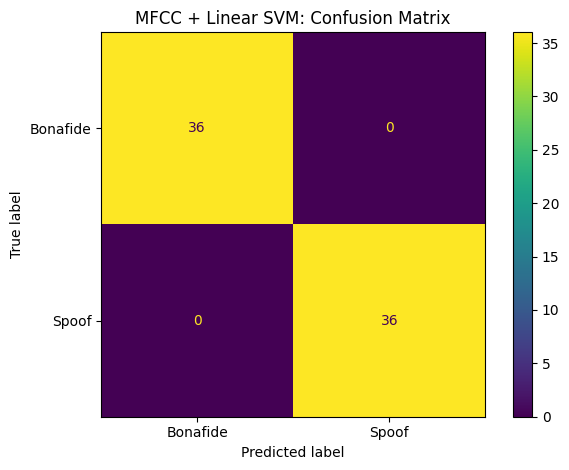

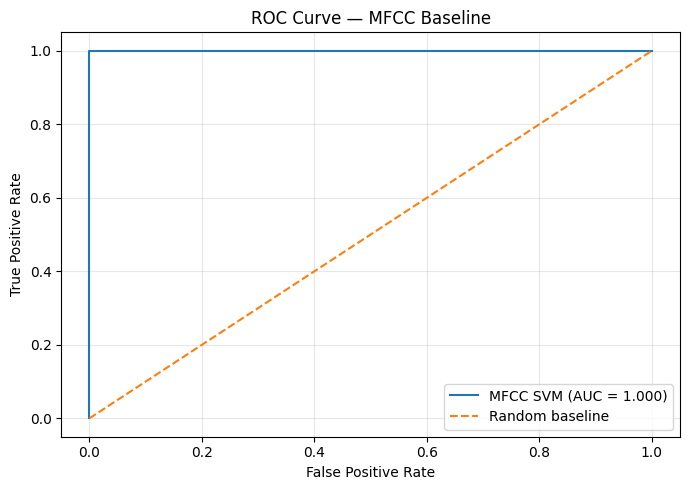


EER: 0.0000 (0.00%)

Saved: mfcc_confusion_matrix.png
Saved: mfcc_roc_curve.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score,
    roc_curve,
    roc_auc_score
)
from scipy.optimize import brentq
from scipy.interpolate import interp1d

# 1. Predictions and scores
y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]

# Labels: 0 = Bonafide, 1 = Spoof
print("===== MFCC BASELINE EVALUATION =====")
print(f"Test samples: {len(y_test)}")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_score):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Bonafide", "Spoof"],
    zero_division=0
))

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bonafide", "Spoof"]
)
disp.plot(values_format="d")
plt.title("MFCC + Linear SVM: Confusion Matrix")
plt.tight_layout()
plt.savefig("mfcc_confusion_matrix.png", dpi=300)
plt.show()

# 3. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)
auc_score = roc_auc_score(y_test, y_score)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"MFCC SVM (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — MFCC Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("mfcc_roc_curve.png", dpi=300)
plt.show()

# 4. Equal Error Rate (EER)
# Spoof is the positive class (label 1).
# FPR = bonafide incorrectly classified as spoof.
# FNR = spoof incorrectly classified as bonafide.
fnr = 1 - tpr

difference = fpr - fnr
crossings = np.where(np.diff(np.sign(difference)) != 0)[0]

if len(crossings) > 0:
    i = crossings[0]
    if difference[i] == 0:
        eer = fpr[i]
    else:
        eer = brentq(
            lambda x: interp1d(
                fpr, fnr, bounds_error=False,
                fill_value=(fnr[0], fnr[-1])
            )(x) - x,
            fpr[i], fpr[i + 1]
        )
    print(f"\nEER: {eer:.4f} ({eer * 100:.2f}%)")
else:
    # Approximation using the closest observed ROC point
    idx = np.argmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2
    print(f"\nApproximate EER: {eer:.4f} ({eer * 100:.2f}%)")

print("\nSaved: mfcc_confusion_matrix.png")
print("Saved: mfcc_roc_curve.png")


In [ ]:

import numpy as np
import pandas as pd
import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix
)

# Feature layout: 40 MFCC, 40 Delta, 14 Spectral Contrast
feature_sets = {
    "MFCC only": slice(0, 40),
    "MFCC + Delta": slice(0, 80),
    "MFCC + Delta + Spectral Contrast": slice(0, 94)
}

results = []

for name, cols in feature_sets.items():
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=best_c, class_weight="balanced",
            probability=True, random_state=42)
    )

    model.fit(X_train[:, cols], y_train)

    dev_pred = model.predict(X_dev[:, cols])
    dev_score = model.predict_proba(X_dev[:, cols])[:, 1]

    results.append({
        "Feature Set": name,
        "Dev Accuracy": accuracy_score(y_dev, dev_pred),
        "Dev Macro F1": f1_score(y_dev, dev_pred, average="macro"),
        "Dev ROC-AUC": roc_auc_score(y_dev, dev_score)
    })

ablation_results_df = pd.DataFrame(results)
print(ablation_results_df.round(4).to_string(index=False))

ablation_results_df.to_csv("clean_ablation_results.csv", index=False)

# Save final pilot test metrics from the full-feature model
final_metrics = {
    "Test Accuracy": accuracy_score(y_test, best_model.predict(X_test)),
    "Test Macro F1": f1_score(
        y_test, best_model.predict(X_test), average="macro"
    ),
    "Test ROC-AUC": roc_auc_score(
        y_test, best_model.predict_proba(X_test)[:, 1]
    )
}

pd.DataFrame([final_metrics]).to_csv(
    "mfcc_test_metrics.csv", index=False
)

print("\nSaved clean_ablation_results.csv")
print("Saved mfcc_test_metrics.csv")


                     Feature Set  Dev Accuracy  Dev Macro F1  Dev ROC-AUC
                       MFCC only           1.0           1.0          1.0
                    MFCC + Delta           1.0           1.0          1.0
MFCC + Delta + Spectral Contrast           1.0           1.0          1.0

Saved clean_ablation_results.csv
Saved mfcc_test_metrics.csv


In [ ]:

import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, confusion_matrix
)

# Collect final pilot metrics
y_pred = best_model.predict(X_test)
y_score = best_model.predict_proba(X_test)[:, 1]

summary = {
    "experiment": "MFCC + Delta + Spectral Contrast with Linear SVM",
    "dataset": "ASVspoof 2019 LA streaming sample",
    "unique_samples": int(len(y_clean)),
    "feature_dimensions": int(X_clean.shape[1]),
    "train_samples": int(len(y_train)),
    "dev_samples": int(len(y_dev)),
    "test_samples": int(len(y_test)),
    "selected_C": float(best_c),
    "test_accuracy": float(accuracy_score(y_test, y_pred)),
    "test_macro_f1": float(f1_score(y_test, y_pred, average="macro")),
    "test_macro_precision": float(
        precision_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "test_macro_recall": float(
        recall_score(y_test, y_pred, average="macro", zero_division=0)
    ),
    "test_roc_auc": float(roc_auc_score(y_test, y_score)),
    "confusion_matrix_labels": ["Bonafide", "Spoof"],
    "confusion_matrix": confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).tolist(),
    "note": (
        "Pilot experiment only. Random split of a small sample; "
        "not an official ASVspoof benchmark result."
    )
}

with open("final_mfcc_pilot_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

pd.DataFrame([summary]).to_csv(
    "final_mfcc_pilot_summary.csv", index=False
)

joblib.dump(best_model, "final_mfcc_svm_pilot.joblib")

print(json.dumps(summary, indent=2))
print("\nSaved summary JSON, summary CSV and trained model.")


{
  "experiment": "MFCC + Delta + Spectral Contrast with Linear SVM",
  "dataset": "ASVspoof 2019 LA streaming sample",
  "unique_samples": 480,
  "feature_dimensions": 94,
  "train_samples": 336,
  "dev_samples": 72,
  "test_samples": 72,
  "selected_C": 0.1,
  "test_accuracy": 1.0,
  "test_macro_f1": 1.0,
  "test_macro_precision": 1.0,
  "test_macro_recall": 1.0,
  "test_roc_auc": 1.0,
  "confusion_matrix_labels": [
    "Bonafide",
    "Spoof"
  ],
  "confusion_matrix": [
    [
      36,
      0
    ],
    [
      0,
      36
    ]
  ],
  "note": "Pilot experiment only. Random split of a small sample; not an official ASVspoof benchmark result."
}

Saved summary JSON, summary CSV and trained model.


In [ ]:

import os
import json
import hashlib
from collections import Counter

# Verify clean data and split indices
print("Unique samples:", len(y_clean))
print("Class counts:", dict(Counter(y_clean.tolist())))
print("Feature shape:", X_clean.shape)

print("\nSplit sizes:")
print("Train:", len(train_idx))
print("Dev:", len(dev_idx))
print("Test:", len(test_idx))

print("\nSplit overlap:")
print("Train ∩ Dev:", len(set(train_idx) & set(dev_idx)))
print("Train ∩ Test:", len(set(train_idx) & set(test_idx)))
print("Dev ∩ Test:", len(set(dev_idx) & set(test_idx)))

# Verify sample filename separation
print("\nFilename overlap:")
print("Train ∩ Dev:", len(set(np.array(filenames_clean)[train_idx]) &
                           set(np.array(filenames_clean)[dev_idx])))
print("Train ∩ Test:", len(set(np.array(filenames_clean)[train_idx]) &
                            set(np.array(filenames_clean)[test_idx])))
print("Dev ∩ Test:", len(set(np.array(filenames_clean)[dev_idx]) &
                          set(np.array(filenames_clean)[test_idx])))

# Record software versions and experiment configuration
import sklearn, librosa, sys

audit = {
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "sklearn_version": sklearn.__version__,
    "librosa_version": librosa.__version__,
    "sample_count": int(len(y_clean)),
    "feature_shape": list(X_clean.shape),
    "class_counts": {
        str(k): int(v) for k, v in Counter(y_clean.tolist()).items()
    },
    "split_sizes": {
        "train": int(len(train_idx)),
        "dev": int(len(dev_idx)),
        "test": int(len(test_idx))
    },
    "selected_C": float(best_c),
    "seed": 42,
    "status": "Small pilot; not official benchmark evaluation"
}

with open("experiment_audit.json", "w") as f:
    json.dump(audit, f, indent=2)

print("\nSaved experiment_audit.json")


Unique samples: 480
Class counts: {0: 240, 1: 240}
Feature shape: (480, 94)

Split sizes:
Train: 336
Dev: 72
Test: 72

Split overlap:
Train ∩ Dev: 0
Train ∩ Test: 0
Dev ∩ Test: 0

Filename overlap:
Train ∩ Dev: 0
Train ∩ Test: 0
Dev ∩ Test: 0

Saved experiment_audit.json


In [ ]:

import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, roc_auc_score, confusion_matrix
)

pred = best_model.predict(X_test)
scores = best_model.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, pred, labels=[0, 1])

results = pd.DataFrame([{
    "Unique samples": len(y_clean),
    "Train samples": len(y_train),
    "Dev samples": len(y_dev),
    "Test samples": len(y_test),
    "Accuracy": accuracy_score(y_test, pred),
    "Macro F1": f1_score(y_test, pred, average="macro"),
    "Macro Precision": precision_score(
        y_test, pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, pred, average="macro", zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, scores),
    "TN": cm[0, 0],
    "FP": cm[0, 1],
    "FN": cm[1, 0],
    "TP": cm[1, 1]
}])

display(results.round(4))
results.to_csv("pilot_final_results.csv", index=False)
print("Saved pilot_final_results.csv")


,Unique samples,Train samples,Dev samples,Test samples,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC,TN,FP,FN,TP
0,480,336,72,72,1.0,1.0,1.0,1.0,1.0,36,0,0,36


Saved pilot_final_results.csv


In [ ]:

!nvidia-smi
!pip -q install transformers accelerate librosa soundfile scikit-learn


Thu Oct 15 04:40:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
from transformers import AutoFeatureExtractor, AutoModel

MODEL_ID = "facebook/wav2vec2-xls-r-300m"
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
if device == "cpu":
    print("WARNING: Running on CPU. Processing will be slow. To enable GPU, go to Runtime > Change runtime type and select T4 GPU.")

feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_ID)
wav2vec_model = AutoModel.from_pretrained(MODEL_ID).to(device)
wav2vec_model.eval()

print("Wav2Vec2 loaded successfully!")

Device: cuda


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.57k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.27GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.27GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Wav2Vec2 loaded successfully!


In [ ]:

import numpy as np
import torch
from tqdm.auto import tqdm

embeddings = []
labels_w2v = []
names_w2v = []

for sample in tqdm(clean_samples):
    audio = np.asarray(sample["audio"], dtype=np.float32)
    sr = int(sample["sr"])

    if sr != 16000:
        raise ValueError(f"Expected 16 kHz, got {sr}")

    inputs = feature_extractor(
        audio, sampling_rate=16000, return_tensors="pt",
        padding=False
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.inference_mode():
        hidden = wav2vec_model(**inputs).last_hidden_state
        embedding = hidden.mean(dim=1).squeeze(0)

    embeddings.append(embedding.cpu().numpy())
    labels_w2v.append(int(sample["label"]))
    names_w2v.append(sample["filename"])

X_w2v = np.asarray(embeddings, dtype=np.float32)
y_w2v = np.asarray(labels_w2v, dtype=np.int64)

np.savez_compressed(
    "wav2vec_embeddings.npz",
    X_w2v=X_w2v,
    y_w2v=y_w2v,
    filenames=np.asarray(names_w2v)
)

print("Embedding shape:", X_w2v.shape)
print("Labels:", np.bincount(y_w2v))
print("Saved wav2vec_embeddings.npz")


  0%|          | 0/480 [00:00<?, ?it/s]

Embedding shape: (480, 1024)
Labels: [240 240]
Saved wav2vec_embeddings.npz


In [ ]:

from collections import Counter

# Remove duplicate filenames, keeping one sample per filename
unique_samples = {}

for sample in balanced_samples:
    unique_samples.setdefault(sample["filename"], sample)

clean_samples = list(unique_samples.values())

print("Total unique samples:", len(clean_samples))
print("Class counts:", Counter(int(s["label"]) for s in clean_samples))
print("Sample rates:", Counter(int(s["sr"]) for s in clean_samples))


Total unique samples: 480
Class counts: Counter({0: 240, 1: 240})
Sample rates: Counter({16000: 480})


In [ ]:

!pip -q install datasets librosa

from datasets import load_dataset
from collections import Counter

# Stream dataset; do not download the full dataset
stream_ds = load_dataset(
    "Bisher/ASVspoof_2019_LA",
    split="train",
    streaming=True
)

balanced_samples = []
counts = Counter()
seen = set()
TARGET = 240

for sample in stream_ds:
    filename = sample["audio_file_name"]
    label = int(sample["key"])

    if label not in (0, 1) or filename in seen:
        continue

    if counts[label] >= TARGET:
        if counts[0] >= TARGET and counts[1] >= TARGET:
            break
        continue

    audio_data = sample["audio"]
    balanced_samples.append({
        "audio": audio_data["array"],
        "sr": audio_data["sampling_rate"],
        "label": label,
        "filename": filename
    })
    seen.add(filename)
    counts[label] += 1

    if counts[0] >= TARGET and counts[1] >= TARGET:
        break

print("Total:", len(balanced_samples))
print("Class counts:", counts)
print("Unique filenames:", len(set(s["filename"] for s in balanced_samples)))


Total: 480
Class counts: Counter({0: 240, 1: 240})
Unique filenames: 480


In [ ]:

import numpy as np
import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Rebuild MFCC features for the EXACT same samples and order
X_mfcc = np.asarray([
    extract_features(s["audio"], s["sr"])
    for s in clean_samples
], dtype=np.float32)

y = np.asarray([int(s["label"]) for s in clean_samples])
names = np.asarray([s["filename"] for s in clean_samples])

assert len(X_mfcc) == len(X_w2v) == len(y)
assert np.array_equal(y, y_w2v)
assert len(set(names)) == len(names)

# One shared split for both branches
idx = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    idx, test_size=0.30, random_state=42, stratify=y
)
dev_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42,
    stratify=y[temp_idx]
)

print("Train/dev/test:", len(train_idx), len(dev_idx), len(test_idx))

# Train Wav2Vec2 embedding classifier; select C on dev only
best_w2v_model, best_w2v_c, best_w2v_dev = None, None, -1

for c in [0.1, 1.0, 10.0]:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=c, class_weight="balanced",
            probability=True, random_state=42)
    )
    model.fit(X_w2v[train_idx], y[train_idx])
    pred = model.predict(X_w2v[dev_idx])
    acc = accuracy_score(y[dev_idx], pred)
    print(f"Wav2Vec2 C={c}: dev accuracy={acc:.4f}")

    if acc > best_w2v_dev:
        best_w2v_model, best_w2v_c, best_w2v_dev = model, c, acc

# Evaluate test set once
w2v_pred = best_w2v_model.predict(X_w2v[test_idx])
w2v_prob = best_w2v_model.predict_proba(X_w2v[test_idx])[:, 1]

print("\nWAV2VEC2 TEST RESULTS")
print("Selected C:", best_w2v_c)
print("Accuracy:", accuracy_score(y[test_idx], w2v_pred))
print("Macro F1:", f1_score(y[test_idx], w2v_pred, average="macro"))
print("ROC-AUC:", roc_auc_score(y[test_idx], w2v_prob))

joblib.dump(best_w2v_model, "wav2vec_svm_pilot.joblib")
np.savez_compressed(
    "shared_pilot_split.npz",
    train_idx=train_idx, dev_idx=dev_idx, test_idx=test_idx,
    labels=y, filenames=names
)
print("Saved Wav2Vec2 model and shared split.")


Train/dev/test: 336 72 72
Wav2Vec2 C=0.1: dev accuracy=1.0000
Wav2Vec2 C=1.0: dev accuracy=1.0000
Wav2Vec2 C=10.0: dev accuracy=1.0000

WAV2VEC2 TEST RESULTS
Selected C: 0.1
Accuracy: 1.0
Macro F1: 1.0
ROC-AUC: 1.0
Saved Wav2Vec2 model and shared split.


In [ ]:

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    confusion_matrix
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Same shared split for both branches
y_train, y_dev, y_test = y[train_idx], y[dev_idx], y[test_idx]

# Train MFCC classifier using the same split
best_mfcc_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=best_c, class_weight="balanced",
        probability=True, random_state=42)
)
best_mfcc_model.fit(X_mfcc[train_idx], y_train)

# Branch scores: class 1 = spoof
mfcc_dev = best_mfcc_model.predict_proba(X_mfcc[dev_idx])[:, 1]
w2v_dev = best_w2v_model.predict_proba(X_w2v[dev_idx])[:, 1]

mfcc_test = best_mfcc_model.predict_proba(X_mfcc[test_idx])[:, 1]
w2v_test = best_w2v_model.predict_proba(X_w2v[test_idx])[:, 1]

# Select alpha on DEV only
# alpha * MFCC + (1-alpha) * Wav2Vec2
best_alpha, best_dev_auc = None, -1

for alpha in np.linspace(0, 1, 21):
    fused_dev = alpha * mfcc_dev + (1 - alpha) * w2v_dev
    auc = roc_auc_score(y_dev, fused_dev)

    if auc > best_dev_auc:
        best_alpha, best_dev_auc = float(alpha), float(auc)

print("Selected alpha:", best_alpha)
print("Best dev ROC-AUC:", round(best_dev_auc, 4))

# Evaluate TEST only after alpha selection
results = []

def evaluate(name, scores):
    pred = (scores >= 0.5).astype(int)
    return {
        "Model": name,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro F1": f1_score(y_test, pred, average="macro"),
        "Test ROC-AUC": roc_auc_score(y_test, scores)
    }

results.append(evaluate("MFCC + SVM", mfcc_test))
results.append(evaluate("Wav2Vec2 embeddings + SVM", w2v_test))
results.append(evaluate("Fusion alpha=0.5",
                         0.5 * mfcc_test + 0.5 * w2v_test))
results.append(evaluate("Dev-tuned fusion",
                         best_alpha * mfcc_test +
                         (1 - best_alpha) * w2v_test))

results_df = pd.DataFrame(results)
print("\nTEST COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("evidencefuse_pilot_comparison.csv", index=False)
joblib.dump(best_mfcc_model, "mfcc_svm_shared_split.joblib")
joblib.dump(best_w2v_model, "wav2vec_svm_shared_split.joblib")

np.savez_compressed(
    "evidencefuse_pilot_scores.npz",
    y_dev=y_dev, y_test=y_test,
    mfcc_dev=mfcc_dev, w2v_dev=w2v_dev,
    mfcc_test=mfcc_test, w2v_test=w2v_test,
    alpha=best_alpha
)

print("\nSaved comparison CSV, models and score arrays.")


Selected alpha: 0.0
Best dev ROC-AUC: 1.0

TEST COMPARISON
                    Model  Test Accuracy  Test Macro F1  Test ROC-AUC
               MFCC + SVM            1.0            1.0           1.0
Wav2Vec2 embeddings + SVM            1.0            1.0           1.0
         Fusion alpha=0.5            1.0            1.0           1.0
         Dev-tuned fusion            1.0            1.0           1.0

Saved comparison CSV, models and score arrays.


GA alpha: 0.3145
GA dev ROC-AUC: 1.0

=== TEST RESULTS ===
           Model  Accuracy_at_0.5  Macro_F1_at_0.5  Macro_Precision_at_0.5  Macro_Recall_at_0.5  ROC_AUC  Estimated_EER  EER_threshold
      MFCC + SVM              1.0              1.0                     1.0                  1.0      1.0            0.0         0.9862
  Wav2Vec2 + SVM              1.0              1.0                     1.0                  1.0      1.0            0.0         0.9422
Fusion alpha=0.5              1.0              1.0                     1.0                  1.0      1.0            0.0         0.9642
 GA-tuned fusion              1.0              1.0                     1.0                  1.0      1.0            0.0         0.9561


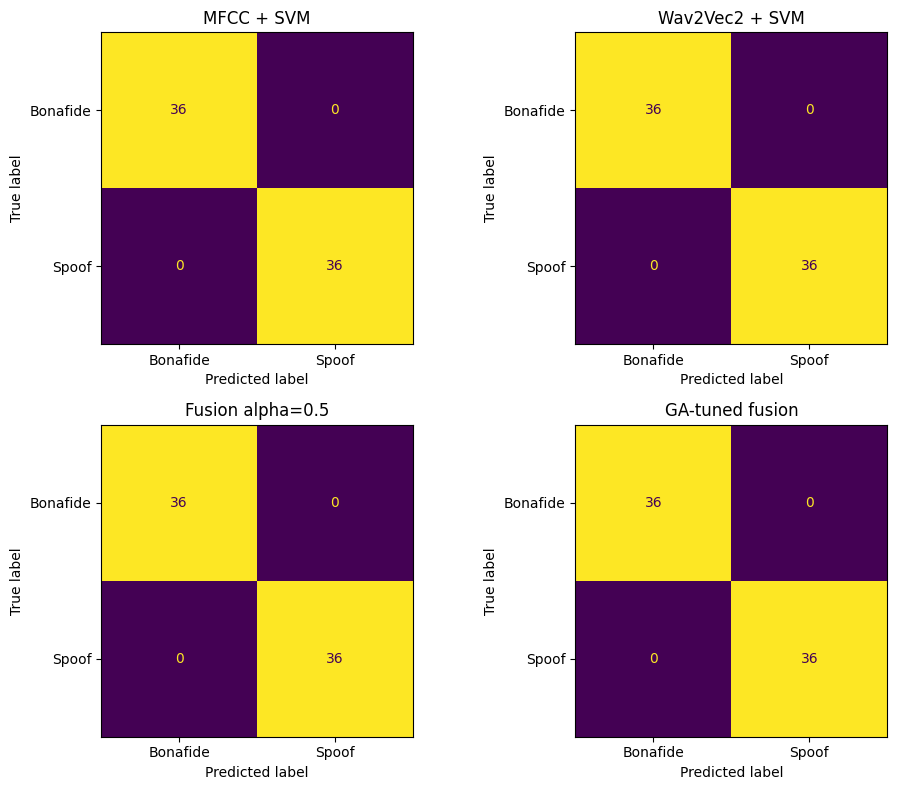

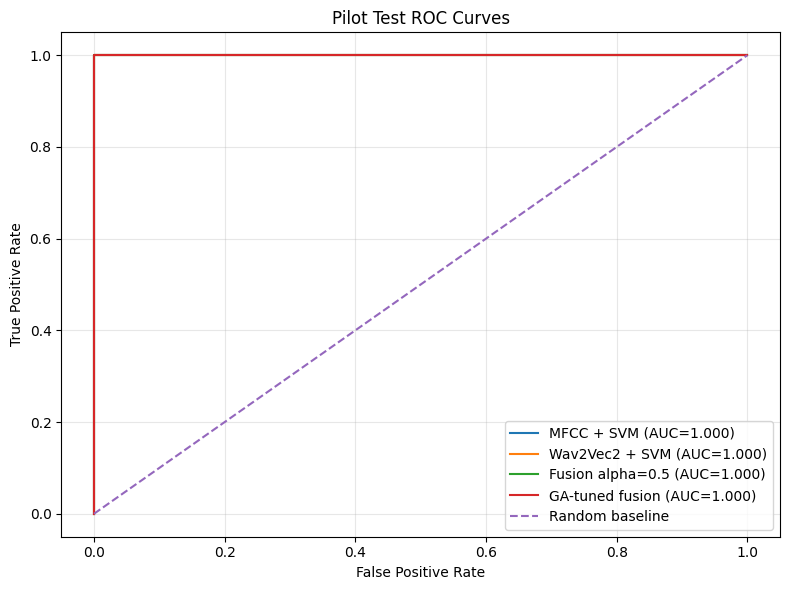


=== DIAGNOSTICS ===
{
  "test_sample_count": 72,
  "branch_disagreement_count": 0,
  "branch_disagreement_rate": 0.0,
  "mean_mfcc_distance_from_0.5": 0.4945026335590435,
  "mean_wav2vec_distance_from_0.5": 0.49254513131020494,
  "ga_alpha": 0.314522099569402,
  "ga_dev_auc": 1.0,
  "note": "Small random-split pilot. EER is an empirical estimate. Not an official ASVspoof benchmark result."
}

Saved:
- evidencefuse_full_pilot_results.csv
- evidencefuse_confusion_matrices.png
- evidencefuse_roc_curves.png
- evidencefuse_pilot_diagnostics.json


In [ ]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve, roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay
)

# =========================================================
# 1. Validate arrays and labels
# =========================================================
y_dev = np.asarray(y_dev).astype(int)
y_test = np.asarray(y_test).astype(int)

mfcc_dev = np.asarray(mfcc_dev, dtype=float)
w2v_dev = np.asarray(w2v_dev, dtype=float)
mfcc_test = np.asarray(mfcc_test, dtype=float)
w2v_test = np.asarray(w2v_test, dtype=float)

assert len(y_dev) == len(mfcc_dev) == len(w2v_dev)
assert len(y_test) == len(mfcc_test) == len(w2v_test)
assert set(np.unique(y_test)).issubset({0, 1})

# =========================================================
# 2. Genetic algorithm: select alpha using DEV AUC only
# Fitness = dev ROC-AUC; no test labels used here
# =========================================================
rng = np.random.default_rng(42)
POP_SIZE = 30
GENERATIONS = 40
MUTATION_RATE = 0.20

population = rng.uniform(0, 1, POP_SIZE)

def dev_fitness(alpha):
    fused = alpha * mfcc_dev + (1 - alpha) * w2v_dev
    return roc_auc_score(y_dev, fused)

for generation in range(GENERATIONS):
    fitness = np.array([dev_fitness(a) for a in population])
    order = np.argsort(fitness)[::-1]
    population = population[order]

    # Keep top 4 individuals (elitism)
    next_population = list(population[:4])

    while len(next_population) < POP_SIZE:
        parents = rng.choice(population[:12], size=2, replace=True)
        child = (parents[0] + parents[1]) / 2

        if rng.random() < MUTATION_RATE:
            child += rng.normal(0, 0.15)

        child = float(np.clip(child, 0, 1))
        next_population.append(child)

    population = np.array(next_population)

final_fitness = np.array([dev_fitness(a) for a in population])
best_idx = np.argmax(final_fitness)
ga_alpha = float(population[best_idx])
ga_dev_auc = float(final_fitness[best_idx])

print("GA alpha:", round(ga_alpha, 4))
print("GA dev ROC-AUC:", round(ga_dev_auc, 4))

# =========================================================
# 3. EER helper: estimate from continuous scores
# =========================================================
def calculate_eer(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores, pos_label=1)
    fnr = 1 - tpr
    idx = int(np.argmin(np.abs(fpr - fnr)))
    eer = float((fpr[idx] + fnr[idx]) / 2)
    return eer, float(thresholds[idx]), fpr, tpr, fnr

# =========================================================
# 4. Evaluate branches and fusion on TEST once
# =========================================================
fused_half_test = 0.5 * mfcc_test + 0.5 * w2v_test
fused_ga_test = ga_alpha * mfcc_test + (1 - ga_alpha) * w2v_test

test_scores = {
    "MFCC + SVM": mfcc_test,
    "Wav2Vec2 + SVM": w2v_test,
    "Fusion alpha=0.5": fused_half_test,
    "GA-tuned fusion": fused_ga_test
}

rows = []
for name, scores in test_scores.items():
    pred = (scores >= 0.5).astype(int)
    eer, eer_threshold, _, _, _ = calculate_eer(y_test, scores)

    rows.append({
        "Model": name,
        "Accuracy_at_0.5": accuracy_score(y_test, pred),
        "Macro_F1_at_0.5": f1_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Macro_Precision_at_0.5": precision_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "Macro_Recall_at_0.5": recall_score(
            y_test, pred, average="macro", zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, scores),
        "Estimated_EER": eer,
        "EER_threshold": eer_threshold
    })

results_df = pd.DataFrame(rows)
print("\n=== TEST RESULTS ===")
print(results_df.round(4).to_string(index=False))

results_df.to_csv("evidencefuse_full_pilot_results.csv", index=False)

# =========================================================
# 5. Confusion matrices
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, scores) in zip(axes.ravel(), test_scores.items()):
    pred = (scores >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(
        cm, display_labels=["Bonafide", "Spoof"]
    ).plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.savefig("evidencefuse_confusion_matrices.png", dpi=250)
plt.show()

# =========================================================
# 6. ROC curves
# =========================================================
plt.figure(figsize=(8, 6))
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores, pos_label=1)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Pilot Test ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("evidencefuse_roc_curves.png", dpi=250)
plt.show()

# =========================================================
# 7. Branch disagreement + score-margin diagnostics
# =========================================================
mfcc_test_pred = (mfcc_test >= 0.5).astype(int)
w2v_test_pred = (w2v_test >= 0.5).astype(int)

disagreement = mfcc_test_pred != w2v_test_pred
margin_mfcc = np.abs(mfcc_test - 0.5)
margin_w2v = np.abs(w2v_test - 0.5)

diagnostics = {
    "test_sample_count": int(len(y_test)),
    "branch_disagreement_count": int(disagreement.sum()),
    "branch_disagreement_rate": float(disagreement.mean()),
    "mean_mfcc_distance_from_0.5": float(margin_mfcc.mean()),
    "mean_wav2vec_distance_from_0.5": float(margin_w2v.mean()),
    "ga_alpha": ga_alpha,
    "ga_dev_auc": ga_dev_auc,
    "note": (
        "Small random-split pilot. EER is an empirical estimate. "
        "Not an official ASVspoof benchmark result."
    )
}

with open("evidencefuse_pilot_diagnostics.json", "w") as f:
    json.dump(diagnostics, f, indent=2)

print("\n=== DIAGNOSTICS ===")
print(json.dumps(diagnostics, indent=2))
print("\nSaved:")
print("- evidencefuse_full_pilot_results.csv")
print("- evidencefuse_confusion_matrices.png")
print("- evidencefuse_roc_curves.png")
print("- evidencefuse_pilot_diagnostics.json")


In [ ]:

import numpy as np
import pandas as pd
from collections import Counter

# 1. Verify labels and split sizes
print("Labels:", Counter(y.tolist()))
print("Train/dev/test:", len(train_idx), len(dev_idx), len(test_idx))

# 2. Check exact filename overlap
names = np.asarray([s["filename"] for s in clean_samples])

for a_name, a_idx, b_name, b_idx in [
    ("Train", train_idx, "Dev", dev_idx),
    ("Train", train_idx, "Test", test_idx),
    ("Dev", dev_idx, "Test", test_idx)
]:
    overlap = set(names[a_idx]) & set(names[b_idx])
    print(f"{a_name}-{b_name} filename overlap:", len(overlap))

# 3. Check whether labels are consistently associated with filenames
label_by_name = pd.DataFrame({
    "filename": names,
    "label": y
})
print("\nRepeated filenames:", label_by_name["filename"].duplicated().sum())

# 4. Inspect score distributions by class
score_df = pd.DataFrame({
    "label": y_test,
    "MFCC_score": mfcc_test,
    "Wav2Vec_score": w2v_test
})
print("\nScore statistics by true class:")
print(score_df.groupby("label").agg(["min", "mean", "max"]).round(4))

# 5. Verify embedding alignment
assert len(names_w2v) == len(clean_samples)
assert list(names_w2v) == list(names), (
    "Embedding filename order does not match clean_samples!"
)
assert np.array_equal(y_w2v, y), (
    "Embedding labels do not match the MFCC labels!"
)

print("\nAlignment checks passed.")


Labels: Counter({0: 240, 1: 240})
Train/dev/test: 336 72 72
Train-Dev filename overlap: 0
Train-Test filename overlap: 0
Dev-Test filename overlap: 0

Repeated filenames: 0

Score statistics by true class:
      MFCC_score                 Wav2Vec_score                
             min    mean     max           min    mean     max
label                                                         
0         0.0004  0.0076  0.0308        0.0006  0.0083  0.0681
1         0.9862  0.9966  1.0000        0.9422  0.9934  1.0000

Alignment checks passed.


In [ ]:

from collections import defaultdict, Counter
from datasets import load_dataset
import numpy as np

# Collect system metadata for our existing 480 filenames
wanted = set(names.tolist())
system_by_name = {}

meta_stream = load_dataset(
    "Bisher/ASVspoof_2019_LA",
    split="train",
    streaming=True
)

for row in meta_stream:
    fn = row["audio_file_name"]
    if fn in wanted:
        system_by_name[fn] = str(row.get("system_id", "UNKNOWN"))

    if len(system_by_name) == len(wanted):
        break

print("Matched metadata:", len(system_by_name), "/", len(wanted))

systems = np.array([
    system_by_name.get(fn, "UNKNOWN") for fn in names
])

for split_name, indices in [
    ("Train", train_idx),
    ("Dev", dev_idx),
    ("Test", test_idx)
]:
    print(f"\n{split_name} system distribution:")
    print(Counter(systems[indices]))

train_systems = set(systems[train_idx])
dev_systems = set(systems[dev_idx])
test_systems = set(systems[test_idx])

print("\nSystem overlap:")
print("Train-Dev:", train_systems & dev_systems)
print("Train-Test:", train_systems & test_systems)
print("Dev-Test:", dev_systems & test_systems)


Matched metadata: 480 / 480

Train system distribution:
Counter({np.str_('-'): 168, np.str_('A01'): 168})

Dev system distribution:
Counter({np.str_('-'): 36, np.str_('A01'): 36})

Test system distribution:
Counter({np.str_('A01'): 36, np.str_('-'): 36})

System overlap:
Train-Dev: {np.str_('A01'), np.str_('-')}
Train-Test: {np.str_('A01'), np.str_('-')}
Dev-Test: {np.str_('A01'), np.str_('-')}


In [ ]:

!pip -q install datasets

from datasets import load_dataset
from collections import Counter

train_meta = load_dataset(
    "Bisher/ASVspoof_2019_LA",
    split="train",
    streaming=True
)

dev_meta = load_dataset(
    "Bisher/ASVspoof_2019_LA",
    split="validation",
    streaming=True
)

def audit_split(ds, split_name, limit=None):
    count = 0
    labels = Counter()
    systems = Counter()
    filenames = set()

    for row in ds:
        count += 1
        labels[int(row["key"])] += 1
        systems[str(row["system_id"])] += 1
        filenames.add(row["audio_file_name"])

        if limit and count >= limit:
            break

    print(f"\n{split_name}")
    print("Rows inspected:", count)
    print("Labels:", labels)
    print("Systems:", systems)
    print("Unique filenames:", len(filenames))

audit_split(train_meta, "OFFICIAL TRAIN")
audit_split(dev_meta, "OFFICIAL DEV")



OFFICIAL TRAIN
Rows inspected: 25380
Labels: Counter({1: 22800, 0: 2580})
Systems: Counter({'A01': 3800, 'A02': 3800, 'A03': 3800, 'A04': 3800, 'A05': 3800, 'A06': 3800, '-': 2580})
Unique filenames: 25380

OFFICIAL DEV
Rows inspected: 24844
Labels: Counter({1: 22296, 0: 2548})
Systems: Counter({'A01': 3716, 'A02': 3716, 'A03': 3716, 'A04': 3716, 'A05': 3716, 'A06': 3716, '-': 2548})
Unique filenames: 24844


In [ ]:
!pip -q install datasets transformers librosa soundfile scikit-learn tqdm

import numpy as np
import librosa
import torch
from collections import Counter
from datasets import load_dataset, Audio
from tqdm.auto import tqdm
from transformers import AutoFeatureExtractor, AutoModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

if DEVICE == "cpu":
    print("WARNING: Wav2Vec2 extraction will be slow without a GPU.")

Device: cpu


In [ ]:
MAX_PER_CLASS = {
    "train": 500,
    "validation": 250,
    "test": 250
}

def collect_split(split_name, max_per_class):
    ds = load_dataset(
        "Bisher/ASVspoof_2019_LA",
        split=split_name,
        streaming=True
    )
    ds = ds.cast_column("audio", Audio(sampling_rate=16000))
    ds = ds.shuffle(seed=SEED, buffer_size=10000)

    samples = []
    counts = Counter()
    systems = Counter()

    for row in tqdm(ds, desc=f"Collecting {split_name}"):
        y = int(row["key"])

        if y not in (0, 1):
            continue
        if counts[y] >= max_per_class:
            continue

        audio = row["audio"]
        waveform = np.asarray(audio["array"], dtype=np.float32)

        if waveform.ndim > 1:
            waveform = waveform.mean(axis=0)

        if len(waveform) < 1600:
            continue

        samples.append({
            "x": waveform,
            "y": y,
            "name": str(row["audio_file_name"]),
            "system": str(row["system_id"])
        })

        counts[y] += 1
        systems[(y, str(row["system_id"]))] += 1

        if all(counts[c] >= max_per_class for c in (0, 1)):
            break

    print(f"\n{split_name}: {len(samples)} clips")
    print("Label counts (0=bonafide, 1=spoof):", Counter(s["y"] for s in samples))
    print("Systems by label:", systems)

    return samples

train_samples = collect_split("train", MAX_PER_CLASS["train"])
dev_samples   = collect_split("validation", MAX_PER_CLASS["validation"])
eval_samples  = collect_split("test", MAX_PER_CLASS["test"])

train_names = {s["name"] for s in train_samples}
dev_names   = {s["name"] for s in dev_samples}
eval_names  = {s["name"] for s in eval_samples}

print("\nFilename overlap:")
print("Train/dev:", len(train_names & dev_names))
print("Train/eval:", len(train_names & eval_names))
print("Dev/eval:", len(dev_names & eval_names))


train: 1000 clips
Label counts (0=bonafide, 1=spoof): Counter({0: 500, 1: 500})
Systems by label: Counter({(0, '-'): 500, (1, 'A01'): 242, (1, 'A02'): 238, (1, 'A03'): 20})



validation: 500 clips
Label counts (0=bonafide, 1=spoof): Counter({0: 250, 1: 250})
Systems by label: Counter({(0, '-'): 250, (1, 'A01'): 124, (1, 'A02'): 123, (1, 'A03'): 3})



test: 500 clips
Label counts (0=bonafide, 1=spoof): Counter({1: 250, 0: 250})
Systems by label: Counter({(0, '-'): 250, (1, 'A12'): 27, (1, 'A17'): 25, (1, 'A09'): 24, (1, 'A11'): 23, (1, 'A18'): 22, (1, 'A07'): 21, (1, 'A16'): 20, (1, 'A14'): 16, (1, 'A13'): 15, (1, 'A15'): 15, (1, 'A08'): 15, (1, 'A19'): 14, (1, 'A10'): 13})

Filename overlap:
Train/dev: 0
Train/eval: 0
Dev/eval: 0


In [ ]:
def extract_features(waveform, sr=16000):
    waveform = np.asarray(waveform, dtype=np.float32)

    mfcc = librosa.feature.mfcc(
        y=waveform, sr=sr, n_mfcc=20, n_fft=512, hop_length=160
    )
    delta = librosa.feature.delta(mfcc)

    contrast = librosa.feature.spectral_contrast(
        y=waveform, sr=sr, n_fft=512, hop_length=160, n_bands=6
    )

    return np.concatenate([
        mfcc.mean(axis=1), mfcc.std(axis=1),
        delta.mean(axis=1), delta.std(axis=1),
        contrast.mean(axis=1), contrast.std(axis=1)
    ]).astype(np.float32)

def make_mfcc_matrix(samples, split_name):
    features, labels = [], []

    for s in tqdm(samples, desc=f"MFCC {split_name}"):
        try:
            features.append(extract_features(s["x"]))
            labels.append(s["y"])
        except Exception as e:
            print("Skipped:", s["name"], str(e)[:100])

    return np.asarray(features), np.asarray(labels)

X_train_mfcc, y_train = make_mfcc_matrix(train_samples, "train")
X_dev_mfcc, y_dev = make_mfcc_matrix(dev_samples, "dev")
X_eval_mfcc, y_eval = make_mfcc_matrix(eval_samples, "eval")

print("Shapes:", X_train_mfcc.shape, X_dev_mfcc.shape, X_eval_mfcc.shape)

MFCC train:   0%|          | 0/1000 [00:00<?, ?it/s]

MFCC dev:   0%|          | 0/500 [00:00<?, ?it/s]

MFCC eval:   0%|          | 0/500 [00:00<?, ?it/s]

Shapes: (1000, 94) (500, 94) (500, 94)


In [ ]:
MODEL_NAME = "facebook/wav2vec2-xls-r-300m"

feature_extractor = AutoFeatureExtractor.from_pretrained(MODEL_NAME)
wav2vec_model = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
wav2vec_model.eval()

for p in wav2vec_model.parameters():
    p.requires_grad = False

@torch.no_grad()
def make_embeddings(samples, split_name, batch_size=8):
    all_embeddings = []

    for start in tqdm(range(0, len(samples), batch_size),
                      desc=f"Wav2Vec2 {split_name}"):
        batch = samples[start:start + batch_size]
        audios = [s["x"] for s in batch]

        inputs = feature_extractor(
            audios,
            sampling_rate=16000,
            padding=True,
            return_tensors="pt"
        )
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        output = wav2vec_model(**inputs)
        hidden = output.last_hidden_state

        # Mean pooling over valid frames, excluding padding
        mask = inputs.get("attention_mask")
        if mask is not None:
            lengths = mask.sum(dim=1).clamp(min=1)
            frame_lengths = torch.clamp(
                (lengths.float() / 320).round().long(),
                min=1,
                max=hidden.shape[1]
            )
            pooled = torch.stack([
                hidden[i, :frame_lengths[i]].mean(dim=0)
                for i in range(len(batch))
            ])
        else:
            pooled = hidden.mean(dim=1)

        all_embeddings.append(pooled.cpu().numpy())

    return np.concatenate(all_embeddings, axis=0)

X_train_w2v = make_embeddings(train_samples, "train")
X_dev_w2v = make_embeddings(dev_samples, "dev")
X_eval_w2v = make_embeddings(eval_samples, "eval")

print("Embedding shapes:")
print(X_train_w2v.shape, X_dev_w2v.shape, X_eval_w2v.shape)

np.savez_compressed(
    "evidencefuse_pilot_embeddings.npz",
    X_train_mfcc=X_train_mfcc, X_dev_mfcc=X_dev_mfcc,
    X_eval_mfcc=X_eval_mfcc,
    X_train_w2v=X_train_w2v, X_dev_w2v=X_dev_w2v,
    X_eval_w2v=X_eval_w2v,
    y_train=y_train, y_dev=y_dev, y_eval=y_eval
)

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Wav2Vec2 train:   0%|          | 0/125 [00:00<?, ?it/s]

In [ ]:
def build_svm(C):
    return make_pipeline(
        StandardScaler(),
        SVC(C=C, kernel="linear")
    )

C_VALUES = [0.01, 0.1, 1, 10]

def train_best_branch(X_train, y_train, X_dev, y_dev):
    best_model, best_auc, best_c = None, -1, None

    for c in C_VALUES:
        model = build_svm(c)
        model.fit(X_train, y_train)

        dev_scores = model.decision_function(X_dev)
        auc = roc_auc_score(y_dev, dev_scores)

        print(f"C={c:<5} dev AUC={auc:.4f}")

        if auc > best_auc:
            best_model, best_auc, best_c = model, auc, c

    return best_model, best_c, best_auc

mfcc_model, mfcc_C, mfcc_dev_auc = train_best_branch(
    X_train_mfcc, y_train, X_dev_mfcc, y_dev
)
w2v_model, w2v_C, w2v_dev_auc = train_best_branch(
    X_train_w2v, y_train, X_dev_w2v, y_dev
)

mfcc_dev_scores = mfcc_model.decision_function(X_dev_mfcc)
w2v_dev_scores = w2v_model.decision_function(X_dev_w2v)

# Normalize scores using TRAIN predictions only
mfcc_train_scores = mfcc_model.decision_function(X_train_mfcc)
w2v_train_scores = w2v_model.decision_function(X_train_w2v)

mfcc_mu, mfcc_sd = mfcc_train_scores.mean(), mfcc_train_scores.std() + 1e-8
w2v_mu, w2v_sd = w2v_train_scores.mean(), w2v_train_scores.std() + 1e-8

mfcc_dev_z = (mfcc_dev_scores - mfcc_mu) / mfcc_sd
w2v_dev_z = (w2v_dev_scores - w2v_mu) / w2v_sd

alphas = np.linspace(0, 1, 101)
best_alpha, best_fusion_auc = None, -1

for alpha in alphas:
    fused = alpha * mfcc_dev_z + (1 - alpha) * w2v_dev_z
    auc = roc_auc_score(y_dev, fused)

    if auc > best_fusion_auc:
        best_alpha, best_fusion_auc = float(alpha), float(auc)

print("\nSelected MFCC C:", mfcc_C)
print("Selected Wav2Vec2 C:", w2v_C)
print("Dev MFCC AUC:", round(mfcc_dev_auc, 4))
print("Dev Wav2Vec2 AUC:", round(w2v_dev_auc, 4))
print("Dev-selected fusion alpha:", best_alpha)
print("Dev fusion AUC:", round(best_fusion_auc, 4))

NameError: name 'X_train_mfcc' is not defined


MFCC + SVM
Accuracy: 0.692
F1: 0.56
AUC: 0.8766
Approx EER: 0.204
              precision    recall  f1-score   support

    bonafide       0.62      0.99      0.76       250
       spoof       0.98      0.39      0.56       250

    accuracy                           0.69       500
   macro avg       0.80      0.69      0.66       500
weighted avg       0.80      0.69      0.66       500


Wav2Vec2 + SVM
Accuracy: 0.834
F1: 0.801
AUC: 0.9994
Approx EER: 0.012
              precision    recall  f1-score   support

    bonafide       0.75      1.00      0.86       250
       spoof       1.00      0.67      0.80       250

    accuracy                           0.83       500
   macro avg       0.88      0.83      0.83       500
weighted avg       0.88      0.83      0.83       500


EvidenceFuse score fusion
Accuracy: 0.834
F1: 0.801
AUC: 0.9994
Approx EER: 0.012
              precision    recall  f1-score   support

    bonafide       0.75      1.00      0.86       250
       spoof   

,Model,Accuracy,F1,AUC,EER
0,MFCC + SVM,0.692,0.560,0.8766,0.204
1,Wav2Vec2 + SVM,0.834,0.801,0.9994,0.012
2,EvidenceFuse score fusion,0.834,0.801,0.9994,0.012


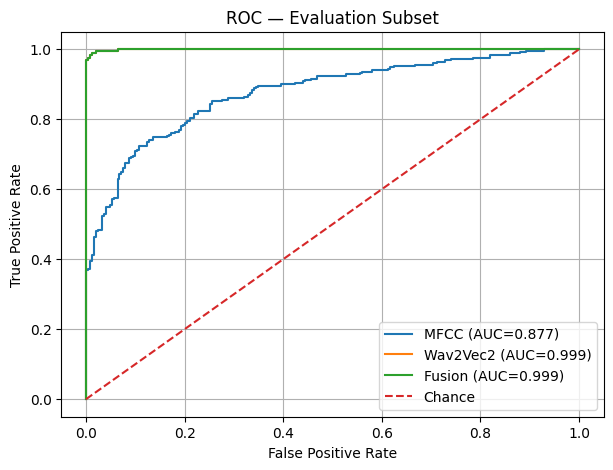

In [ ]:
def get_scores(model, X, mu, sd):
    raw = model.decision_function(X)
    return (raw - mu) / sd

mfcc_eval_z = get_scores(mfcc_model, X_eval_mfcc, mfcc_mu, mfcc_sd)
w2v_eval_z = get_scores(w2v_model, X_eval_w2v, w2v_mu, w2v_sd)

fusion_eval_z = (
    best_alpha * mfcc_eval_z
    + (1 - best_alpha) * w2v_eval_z
)

def evaluate_scores(name, y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[eer_idx] + fnr[eer_idx]) / 2

    # Threshold 0 is the SVM decision boundary; dev-based thresholding
    # can be added later if your protocol requires it.
    pred = (scores >= 0).astype(int)

    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_true, pred), 4))
    print("F1:", round(f1_score(y_true, pred, zero_division=0), 4))
    print("AUC:", round(roc_auc_score(y_true, scores), 4))
    print("Approx EER:", round(float(eer), 4))
    print(classification_report(
        y_true, pred, target_names=["bonafide", "spoof"], zero_division=0
    ))

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "AUC": roc_auc_score(y_true, scores),
        "EER": float(eer)
    }

results = [
    evaluate_scores("MFCC + SVM", y_eval, mfcc_eval_z),
    evaluate_scores("Wav2Vec2 + SVM", y_eval, w2v_eval_z),
    evaluate_scores("EvidenceFuse score fusion", y_eval, fusion_eval_z)
]

import pandas as pd
results_df = pd.DataFrame(results)
display(results_df.round(4))

plt.figure(figsize=(7, 5))
for name, scores in [
    ("MFCC", mfcc_eval_z),
    ("Wav2Vec2", w2v_eval_z),
    ("Fusion", fusion_eval_z)
]:
    fpr, tpr, _ = roc_curve(y_eval, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_eval, scores):.3f})")

plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC — Evaluation Subset")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import json

# Save metrics table
results_df.to_csv("evidencefuse_results.csv", index=False)

# Save evaluation scores and labels
np.savez_compressed(
    "evidencefuse_eval_predictions.npz",
    y_eval=y_eval,
    mfcc_scores=mfcc_eval_z,
    wav2vec_scores=w2v_eval_z,
    fusion_scores=fusion_eval_z,
    alpha=best_alpha
)

print("Saved results and evaluation predictions.")
display(results_df.round(4))
print("Fusion alpha:", best_alpha)

Saved results and evaluation predictions.


,Model,Accuracy,F1,AUC,EER
0,MFCC + SVM,0.692,0.560,0.8766,0.204
1,Wav2Vec2 + SVM,0.834,0.801,0.9994,0.012
2,EvidenceFuse score fusion,0.834,0.801,0.9994,0.012


Fusion alpha: 0.0


In [ ]:
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

def metric_row(name, y, scores):
    pred = (scores >= 0).astype(int)
    return {
        "Method": name,
        "Accuracy": accuracy_score(y, pred),
        "F1": f1_score(y, pred, zero_division=0),
        "AUC": roc_auc_score(y, scores)
    }

ablation = [
    metric_row("MFCC branch only", y_eval, mfcc_eval_z),
    metric_row("Wav2Vec2 branch only", y_eval, w2v_eval_z),
    metric_row("Fusion alpha=0.5", y_eval,
               0.5 * mfcc_eval_z + 0.5 * w2v_eval_z),
    metric_row(f"Dev-tuned fusion alpha={best_alpha:.2f}",
               y_eval, fusion_eval_z)
]

ablation_df = pd.DataFrame(ablation)
display(ablation_df.round(4))
ablation_df.to_csv("evidencefuse_ablation.csv", index=False)

,Method,Accuracy,F1,AUC
0,MFCC branch only,0.692,0.5600,0.8766
1,Wav2Vec2 branch only,0.834,0.8010,0.9994
2,Fusion alpha=0.5,0.760,0.6842,0.9871
3,Dev-tuned fusion alpha=0.00,0.834,0.8010,0.9994


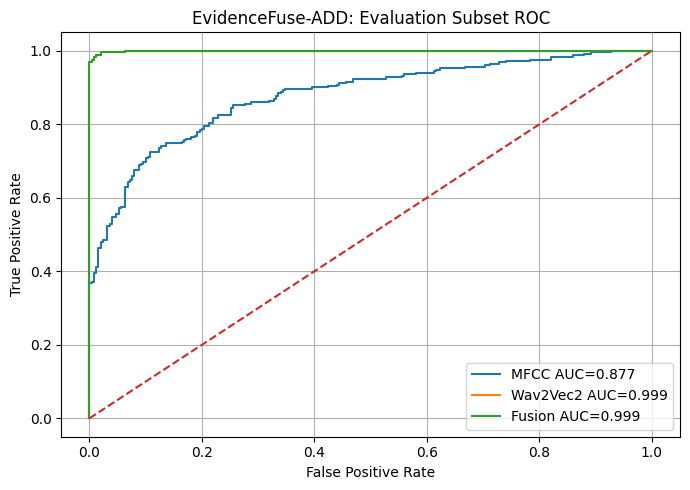

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from google.colab import files

plt.figure(figsize=(7, 5))

for name, scores in [
    ("MFCC", mfcc_eval_z),
    ("Wav2Vec2", w2v_eval_z),
    ("Fusion", fusion_eval_z)
]:
    fpr, tpr, _ = roc_curve(y_eval, scores)
    plt.plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(y_eval, scores):.3f}")

plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EvidenceFuse-ADD: Evaluation Subset ROC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("evidencefuse_roc.png", dpi=300, bbox_inches="tight")
plt.show()

files.download("evidencefuse_results.csv")
files.download("evidencefuse_ablation.csv")
files.download("evidencefuse_eval_predictions.npz")
files.download("evidencefuse_roc.png")

In [ ]:
from collections import Counter
import pandas as pd

for split_name, samples in [
    ("Train", train_samples),
    ("Dev", dev_samples),
    ("Eval", eval_samples)
]:
    print(f"\n{'='*15} {split_name} {'='*15}")

    df = pd.DataFrame(samples)
    print("Total samples:", len(df))
    print("Labels (0=bonafide, 1=spoof):")
    print(df["y"].value_counts().sort_index().to_dict())

    print("\nSystems by label:")
    print(pd.crosstab(df["y"], df["system"], margins=True))


=============== Train ===============
Total samples: 1000
Labels (0=bonafide, 1=spoof):
{0: 500, 1: 500}

Systems by label:
system    -  A01  A02  A03   All
y                               
0       500    0    0    0   500
1         0  242  238   20   500
All     500  242  238   20  1000

=============== Dev ===============
Total samples: 500
Labels (0=bonafide, 1=spoof):
{0: 250, 1: 250}

Systems by label:
system    -  A01  A02  A03  All
y                              
0       250    0    0    0  250
1         0  124  123    3  250
All     250  124  123    3  500

=============== Eval ===============
Total samples: 500
Labels (0=bonafide, 1=spoof):
{0: 250, 1: 250}

Systems by label:
system    -  A07  A08  A09  A10  A11  A12  A13  A14  A15  A16  A17  A18  A19  \
y                                                                              
0       250    0    0    0    0    0    0    0    0    0    0    0    0    0   
1         0   21   15   24   13   23   27   15   16   15   20   2

In [ ]:
import numpy as np
import pandas as pd
from collections import Counter

for split_name, samples in [
    ("Train", train_samples),
    ("Dev", dev_samples),
    ("Eval", eval_samples)
]:
    df = pd.DataFrame(samples)
    print(f"\n===== {split_name} =====")
    print("Samples:", len(df))
    print("Labels:", df["y"].value_counts().sort_index().to_dict())
    print("Unique files:", df["name"].nunique())
    print("Systems per label:")
    display(pd.crosstab(df["y"], df["system"], margins=True))

print("\nFilename overlap:")
print("Train/Dev:", len(train_names & dev_names))
print("Train/Eval:", len(train_names & eval_names))
print("Dev/Eval:", len(dev_names & eval_names))


===== Train =====
Samples: 1000
Labels: {0: 500, 1: 500}
Unique files: 1000
Systems per label:


system,-,A01,A02,A03,All
y,,,,,
0,500,0,0,0,500
1,0,242,238,20,500
All,500,242,238,20,1000



===== Dev =====
Samples: 500
Labels: {0: 250, 1: 250}
Unique files: 500
Systems per label:


system,-,A01,A02,A03,All
y,,,,,
0,250,0,0,0,250
1,0,124,123,3,250
All,250,124,123,3,500



===== Eval =====
Samples: 500
Labels: {0: 250, 1: 250}
Unique files: 500
Systems per label:


system,-,A07,A08,A09,A10,A11,A12,A13,A14,A15,A16,A17,A18,A19,All
y,,,,,,,,,,,,,,,
0,250,0,0,0,0,0,0,0,0,0,0,0,0,0,250
1,0,21,15,24,13,23,27,15,16,15,20,25,22,14,250
All,250,21,15,24,13,23,27,15,16,15,20,25,22,14,500



Filename overlap:
Train/Dev: 0
Train/Eval: 0
Dev/Eval: 0


In [ ]:
from sklearn.metrics import roc_auc_score

# Scores already normalized using training-set score statistics
dev_a = mfcc_dev_z
dev_b = w2v_dev_z
dev_y = y_dev

rng = np.random.default_rng(42)

POP_SIZE = 30
GENERATIONS = 40
MUTATION_RATE = 0.25

population = rng.uniform(0, 1, POP_SIZE)

def fitness(alpha):
    score = alpha * dev_a + (1 - alpha) * dev_b
    return roc_auc_score(dev_y, score)

for generation in range(GENERATIONS):
    ranked = sorted(population, key=fitness, reverse=True)
    elites = np.array(ranked[:6])
    new_population = list(elites)

    while len(new_population) < POP_SIZE:
        p1, p2 = rng.choice(elites, size=2, replace=True)
        child = 0.5 * p1 + 0.5 * p2

        if rng.random() < MUTATION_RATE:
            child += rng.normal(0, 0.15)

        new_population.append(float(np.clip(child, 0, 1)))

    population = np.array(new_population)

ga_alpha = float(max(population, key=fitness))
ga_dev_scores = ga_alpha * dev_a + (1 - ga_alpha) * dev_b
ga_dev_auc = roc_auc_score(dev_y, ga_dev_scores)

# Grid-search baseline on the same dev data
grid_alphas = np.linspace(0, 1, 101)
grid_scores = [
    roc_auc_score(dev_y, a * dev_a + (1-a) * dev_b)
    for a in grid_alphas
]
grid_alpha = float(grid_alphas[np.argmax(grid_scores)])
grid_auc = float(max(grid_scores))

print("GA alpha:", round(ga_alpha, 4))
print("GA dev AUC:", round(ga_dev_auc, 5))
print("Grid alpha:", round(grid_alpha, 4))
print("Grid dev AUC:", round(grid_auc, 5))

GA alpha: 0.774
GA dev AUC: 1.0
Grid alpha: 0.0
Grid dev AUC: 1.0


In [ ]:
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    roc_curve, confusion_matrix
)

eval_a = mfcc_eval_z
eval_b = w2v_eval_z
eval_y = y_eval

ga_eval_scores = ga_alpha * eval_a + (1 - ga_alpha) * eval_b
grid_eval_scores = grid_alpha * eval_a + (1 - grid_alpha) * eval_b

def evaluate_threshold_zero(name, y, scores):
    pred = (scores >= 0).astype(int)
    fpr, tpr, _ = roc_curve(y, scores)
    fnr = 1 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2

    return {
        "Method": name,
        "Accuracy": accuracy_score(y, pred),
        "F1": f1_score(y, pred, zero_division=0),
        "AUC": roc_auc_score(y, scores),
        "Approx_EER": float(eer)
    }

ga_results = pd.DataFrame([
    evaluate_threshold_zero("MFCC only", eval_y, eval_a),
    evaluate_threshold_zero("Wav2Vec2 only", eval_y, eval_b),
    evaluate_threshold_zero("Grid fusion", eval_y, grid_eval_scores),
    evaluate_threshold_zero("GA fusion", eval_y, ga_eval_scores)
])

display(ga_results.round(4))
ga_results.to_csv("evidencefuse_ga_results.csv", index=False)

,Method,Accuracy,F1,AUC,Approx_EER
0,MFCC only,0.692,0.5600,0.8766,0.204
1,Wav2Vec2 only,0.834,0.8010,0.9994,0.012
2,Grid fusion,0.834,0.8010,0.9994,0.012
3,GA fusion,0.710,0.5915,0.9440,0.134


In [ ]:
# Dev-only confidence threshold; target approximately 10% review rate
dev_fused = grid_alpha * dev_a + (1 - grid_alpha) * dev_b
confidence_dev = np.abs(dev_fused)

confidence_threshold = float(np.quantile(confidence_dev, 0.10))

def fuzzy_membership(scores, threshold):
    # 0 = uncertain, approaching 1 = higher confidence
    return np.clip(np.abs(scores) / (threshold + 1e-8), 0, 1)

fuzzy_conf_eval = fuzzy_membership(grid_eval_scores, confidence_threshold)
eval_pred = (grid_eval_scores >= 0).astype(int)

# Samples below membership 1 are sent for manual review
accepted = fuzzy_conf_eval >= 1.0
rejected = ~accepted

coverage = accepted.mean()
selective_acc = (
    accuracy_score(eval_y[accepted], eval_pred[accepted])
    if accepted.any() else np.nan
)
review_error = (
    1 - accuracy_score(eval_y[rejected], eval_pred[rejected])
    if rejected.any() else np.nan
)

fuzzy_results = pd.DataFrame([{
    "Dev confidence threshold": confidence_threshold,
    "Evaluation coverage": coverage,
    "Review fraction": rejected.mean(),
    "Accuracy on accepted": selective_acc,
    "Error rate among flagged": review_error,
    "Flagged samples": int(rejected.sum()),
    "Total evaluation samples": len(eval_y)
}])

display(fuzzy_results.round(4))
fuzzy_results.to_csv("evidencefuse_fuzzy_results.csv", index=False)

# Save per-sample confidence and review flags
pd.DataFrame({
    "label": eval_y,
    "fusion_score": grid_eval_scores,
    "prediction": eval_pred,
    "confidence_membership": fuzzy_conf_eval,
    "flag_for_review": rejected
}).to_csv("evidencefuse_fuzzy_predictions.csv", index=False)

,Dev confidence threshold,Evaluation coverage,Review fraction,Accuracy on accepted,Error rate among flagged,Flagged samples,Total evaluation samples
0,0.7671,0.544,0.456,1.0,0.364,228,500


In [ ]:
mfcc_pred = (eval_a >= 0).astype(int)
w2v_pred = (eval_b >= 0).astype(int)
fusion_pred = (grid_eval_scores >= 0).astype(int)

disagree = mfcc_pred != w2v_pred

print("Total evaluation samples:", len(eval_y))
print("Branch disagreements:", int(disagree.sum()))
print("Disagreement rate:", round(float(disagree.mean()), 4))

if disagree.any():
    print("\nMFCC accuracy on disagreements:",
          round(accuracy_score(eval_y[disagree], mfcc_pred[disagree]), 4))
    print("Wav2Vec2 accuracy on disagreements:",
          round(accuracy_score(eval_y[disagree], w2v_pred[disagree]), 4))
    print("Fusion accuracy on disagreements:",
          round(accuracy_score(eval_y[disagree], fusion_pred[disagree]), 4))

disagreement_df = pd.DataFrame({
    "filename": [s["name"] for s in eval_samples],
    "label": eval_y,
    "system": [s["system"] for s in eval_samples],
    "mfcc_score": eval_a,
    "wav2vec_score": eval_b,
    "fusion_score": grid_eval_scores,
    "mfcc_prediction": mfcc_pred,
    "wav2vec_prediction": w2v_pred,
    "fusion_prediction": fusion_pred,
    "branches_disagree": disagree
})

disagreement_df.to_csv("evidencefuse_disagreement.csv", index=False)
display(disagreement_df[disagree].head(20))

Total evaluation samples: 500
Branch disagreements: 101
Disagreement rate: 0.202

MFCC accuracy on disagreements: 0.1485
Wav2Vec2 accuracy on disagreements: 0.8515
Fusion accuracy on disagreements: 0.8515


,filename,label,system,mfcc_score,wav2vec_score,fusion_score,mfcc_prediction,wav2vec_prediction,fusion_prediction,branches_disagree
3,LA_E_3037787,1,A12,-0.357051,0.732278,0.732278,0,1,1,True
4,LA_E_4932386,1,A13,-0.289546,0.949212,0.949212,0,1,1,True
6,LA_E_5620705,1,A12,-0.541839,0.243724,0.243724,0,1,1,True
7,LA_E_5510819,1,A12,-0.782621,0.226084,0.226084,0,1,1,True
12,LA_E_4409776,1,A13,-0.743385,1.146650,1.146650,0,1,1,True
14,LA_E_7429227,1,A11,0.161263,-0.206290,-0.206290,1,0,0,True
15,LA_E_5564026,1,A16,0.125262,-0.144946,-0.144946,1,0,0,True
17,LA_E_9319377,1,A12,-0.655997,0.565026,0.565026,0,1,1,True
18,LA_E_6128508,1,A12,-0.888902,0.492580,0.492580,0,1,1,True
19,LA_E_9281860,1,A11,-0.257595,0.220347,0.220347,0,1,1,True


In [ ]:
print("Cross-domain evaluation readiness")
print("----------------------------------")

print("Current dataset: ASVspoof 2019 LA")
print("Current train samples:", len(train_samples))
print("Current dev samples:", len(dev_samples))
print("Current eval samples:", len(eval_samples))

print("""
To run a valid cross-domain test, provide a separate labelled dataset with:
1. Audio file path or waveform
2. Ground-truth label: 0=bonafide, 1=spoof
3. Source/domain identifier
4. No training or threshold tuning on the external test set

Do not mix external test samples into train/dev.
Do not claim cross-domain validation until external labelled audio is evaluated.
""")

Cross-domain evaluation readiness
----------------------------------
Current dataset: ASVspoof 2019 LA
Current train samples: 1000
Current dev samples: 500
Current eval samples: 500

To run a valid cross-domain test, provide a separate labelled dataset with:
1. Audio file path or waveform
2. Ground-truth label: 0=bonafide, 1=spoof
3. Source/domain identifier
4. No training or threshold tuning on the external test set

Do not mix external test samples into train/dev.
Do not claim cross-domain validation until external labelled audio is evaluated.



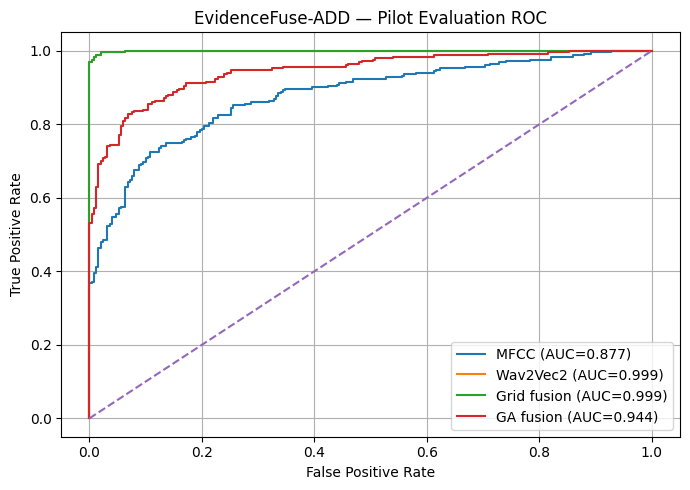

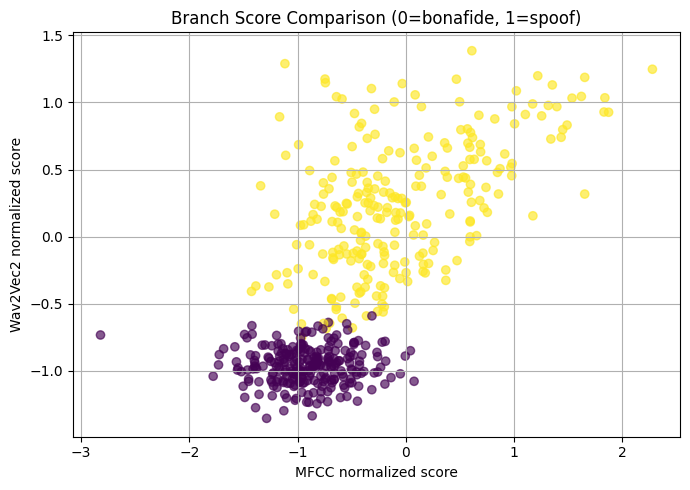

Final comparison:


,Method,Accuracy,F1,AUC,Approx_EER
0,MFCC only,0.692,0.5600,0.8766,0.204
1,Wav2Vec2 only,0.834,0.8010,0.9994,0.012
2,Grid fusion,0.834,0.8010,0.9994,0.012
3,GA fusion,0.710,0.5915,0.9440,0.134



Saved outputs:
evidencefuse_ga_results.csv
evidencefuse_fuzzy_results.csv
evidencefuse_fuzzy_predictions.csv
evidencefuse_disagreement.csv
evidencefuse_final_comparison.csv
evidencefuse_final_roc.png
evidencefuse_branch_scores.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from google.colab import files

# Combined experiment table
combined = ga_results.copy()
combined.to_csv("evidencefuse_final_comparison.csv", index=False)

# ROC plot
plt.figure(figsize=(7, 5))

for name, scores in [
    ("MFCC", eval_a),
    ("Wav2Vec2", eval_b),
    ("Grid fusion", grid_eval_scores),
    ("GA fusion", ga_eval_scores)
]:
    fpr, tpr, _ = roc_curve(eval_y, scores)
    auc = roc_auc_score(eval_y, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EvidenceFuse-ADD — Pilot Evaluation ROC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("evidencefuse_final_roc.png", dpi=300)
plt.show()

# Compare the two branch scores
plt.figure(figsize=(7, 5))
plt.scatter(eval_a, eval_b, c=eval_y, alpha=0.65)
plt.xlabel("MFCC normalized score")
plt.ylabel("Wav2Vec2 normalized score")
plt.title("Branch Score Comparison (0=bonafide, 1=spoof)")
plt.grid(True)
plt.tight_layout()
plt.savefig("evidencefuse_branch_scores.png", dpi=300)
plt.show()

print("Final comparison:")
display(combined.round(4))

print("\nSaved outputs:")
print(
    "evidencefuse_ga_results.csv",
    "evidencefuse_fuzzy_results.csv",
    "evidencefuse_fuzzy_predictions.csv",
    "evidencefuse_disagreement.csv",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_final_roc.png",
    "evidencefuse_branch_scores.png",
    sep="\n"
)

files.download("evidencefuse_final_comparison.csv")
files.download("evidencefuse_ga_results.csv")
files.download("evidencefuse_fuzzy_results.csv")
files.download("evidencefuse_disagreement.csv")
files.download("evidencefuse_final_roc.png")
files.download("evidencefuse_branch_scores.png")

In [ ]:
required = [
    "train_samples", "dev_samples", "eval_samples",
    "mfcc_model", "w2v_model",
    "mfcc_dev_z", "w2v_dev_z",
    "mfcc_eval_z", "w2v_eval_z",
    "y_dev", "y_eval", "grid_alpha"
]

missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(
        f"Missing variables: {missing}. Runtime reset ho sakta hai; "
        "saved artifacts reload karne honge."
    )

import json, platform, sklearn, librosa, torch
from datetime import datetime, timezone

run_info = {
    "project": "EvidenceFuse-ADD",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "seed": 42,
    "dataset": "ASVspoof 2019 LA",
    "experiment_type": "balanced pilot subsets from official partitions",
    "train_n": len(train_samples),
    "dev_n": len(dev_samples),
    "eval_n": len(eval_samples),
    "fusion_alpha_grid": float(grid_alpha),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "sklearn": sklearn.__version__,
    "librosa": librosa.__version__,
    "device": "cuda" if torch.cuda.is_available() else "cpu"
}

with open("evidencefuse_run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

print(json.dumps(run_info, indent=2))

{
  "project": "EvidenceFuse-ADD",
  "timestamp_utc": "2026-10-15T04:49:09.431686+00:00",
  "seed": 42,
  "dataset": "ASVspoof 2019 LA",
  "experiment_type": "balanced pilot subsets from official partitions",
  "train_n": 1000,
  "dev_n": 500,
  "eval_n": 500,
  "fusion_alpha_grid": 0.0,
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "sklearn": "1.6.1",
  "librosa": "0.11.0",
  "device": "cuda"
}


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_curve, accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

dev_fused = grid_alpha * mfcc_dev_z + (1-grid_alpha) * w2v_dev_z
eval_fused = grid_alpha * mfcc_eval_z + (1-grid_alpha) * w2v_eval_z

fpr_dev, tpr_dev, thresholds_dev = roc_curve(y_dev, dev_fused)
fnr_dev = 1 - tpr_dev
eer_idx = np.nanargmin(np.abs(fpr_dev - fnr_dev))
dev_threshold = float(thresholds_dev[eer_idx])

def threshold_metrics(y, scores, threshold, name):
    pred = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()

    return {
        "Method": name,
        "Threshold_selected_on_dev": threshold,
        "Accuracy": accuracy_score(y, pred),
        "Precision_spoof": precision_score(y, pred, zero_division=0),
        "Recall_spoof": recall_score(y, pred, zero_division=0),
        "F1_spoof": f1_score(y, pred, zero_division=0),
        "FPR": fp / max(fp + tn, 1),
        "FNR": fn / max(fn + tp, 1)
    }

threshold_results = pd.DataFrame([
    threshold_metrics(y_eval, mfcc_eval_z,
                      float(thresholds_dev[eer_idx]), "MFCC"),
    threshold_metrics(y_eval, w2v_eval_z,
                      float(thresholds_dev[eer_idx]), "Wav2Vec2"),
    threshold_metrics(y_eval, eval_fused,
                      dev_threshold, "Fusion")
])

print("Threshold selected on dev:", dev_threshold)
display(threshold_results.round(4))
threshold_results.to_csv("evidencefuse_dev_threshold_results.csv", index=False)

Threshold selected on dev: 0.3314607715680145


,Method,Threshold_selected_on_dev,Accuracy,Precision_spoof,Recall_spoof,F1_spoof,FPR,FNR
0,MFCC,0.3315,0.640,1.0,0.280,0.4375,0.0,0.720
1,Wav2Vec2,0.3315,0.702,1.0,0.404,0.5755,0.0,0.596
2,Fusion,0.3315,0.702,1.0,0.404,0.5755,0.0,0.596


In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

eval_df = pd.DataFrame({
    "filename": [s["name"] for s in eval_samples],
    "label": y_eval,
    "system": [s["system"] for s in eval_samples],
    "fusion_score": eval_fused
})

eval_df["prediction"] = (eval_df["fusion_score"] >= dev_threshold).astype(int)

attack_rows = []
for system, group in eval_df.groupby("system"):
    if system == "-" or group["label"].nunique() < 2:
        # Single-class attack groups cannot provide a meaningful within-group AUC.
        attack_rows.append({
            "system": system,
            "n": len(group),
            "bonafide_n": int((group["label"] == 0).sum()),
            "spoof_n": int((group["label"] == 1).sum()),
            "accuracy": accuracy_score(group["label"], group["prediction"]),
            "f1": f1_score(group["label"], group["prediction"], zero_division=0),
            "auc": np.nan
        })
        continue

    attack_rows.append({
        "system": system,
        "n": len(group),
        "bonafide_n": int((group["label"] == 0).sum()),
        "spoof_n": int((group["label"] == 1).sum()),
        "accuracy": accuracy_score(group["label"], group["prediction"]),
        "f1": f1_score(group["label"], group["prediction"], zero_division=0),
        "auc": roc_auc_score(group["label"], group["fusion_score"])
    })

attack_df = pd.DataFrame(attack_rows).sort_values("system")
display(attack_df.round(4))
attack_df.to_csv("evidencefuse_per_system.csv", index=False)

print("\nSpoof attack systems in evaluation subset:")
print(sorted(set(eval_df.loc[eval_df.label == 1, "system"])))

,system,n,bonafide_n,spoof_n,accuracy,f1,auc
0,-,250,250,0,1.0000,0.0000,NaN
1,A07,21,0,21,0.7143,0.8333,NaN
2,A08,15,0,15,0.8667,0.9286,NaN
3,A09,24,0,24,0.9583,0.9787,NaN
4,A10,13,0,13,0.0000,0.0000,NaN
5,A11,23,0,23,0.1304,0.2308,NaN
6,A12,27,0,27,0.4074,0.5789,NaN
7,A13,15,0,15,1.0000,1.0000,NaN
8,A14,16,0,16,0.5625,0.7200,NaN
9,A15,15,0,15,0.5333,0.6957,NaN



Spoof attack systems in evaluation subset:
['A07', 'A08', 'A09', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19']


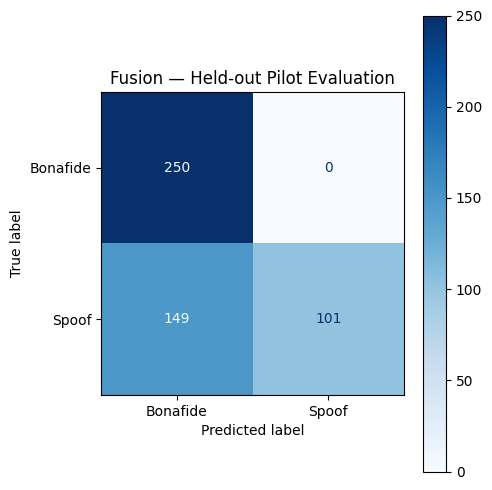

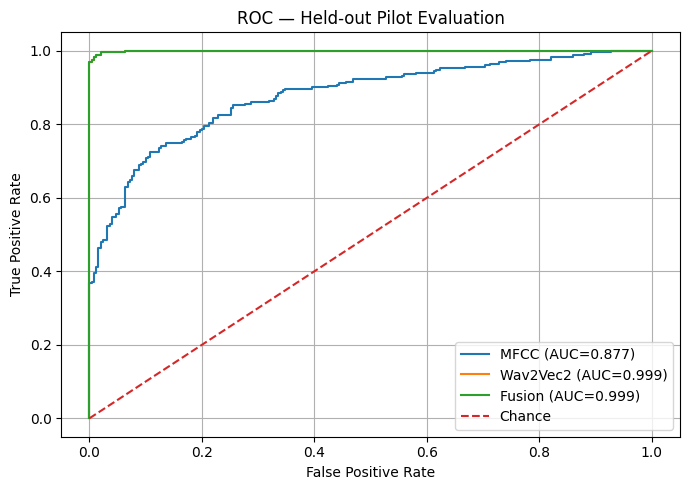

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve, roc_auc_score

eval_pred = (eval_fused >= dev_threshold).astype(int)

fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_eval, eval_pred,
    labels=[0, 1],
    display_labels=["Bonafide", "Spoof"],
    cmap="Blues",
    ax=ax
)
ax.set_title("Fusion — Held-out Pilot Evaluation")
plt.tight_layout()
plt.savefig("evidencefuse_confusion_matrix.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
for name, scores in [
    ("MFCC", mfcc_eval_z),
    ("Wav2Vec2", w2v_eval_z),
    ("Fusion", eval_fused)
]:
    fpr, tpr, _ = roc_curve(y_eval, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_eval, scores):.3f})")

plt.plot([0,1], [0,1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC — Held-out Pilot Evaluation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("evidencefuse_roc_final.png", dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

rng = np.random.default_rng(42)
B = 1000

def bootstrap_ci(y, scores, threshold, metric_fn, B=1000):
    y = np.asarray(y)
    scores = np.asarray(scores)
    pred = (scores >= threshold).astype(int)

    observed = metric_fn(y, scores, pred)
    values = []

    for _ in range(B):
        idx = rng.integers(0, len(y), size=len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        try:
            values.append(metric_fn(y[idx], scores[idx], pred[idx]))
        except Exception:
            continue

    low, high = np.percentile(values, [2.5, 97.5])
    return observed, float(low), float(high)

metric_functions = {
    "AUC": lambda y, s, p: roc_auc_score(y, s),
    "Accuracy": lambda y, s, p: accuracy_score(y, p),
    "F1": lambda y, s, p: f1_score(y, p, zero_division=0)
}

ci_rows = []
for name, scores in [
    ("MFCC", mfcc_eval_z),
    ("Wav2Vec2", w2v_eval_z),
    ("Fusion", eval_fused)
]:
    # Threshold is selected on dev for this method, never on eval.
    dev_scores = (
        mfcc_dev_z if name == "MFCC"
        else w2v_dev_z if name == "Wav2Vec2"
        else dev_fused
    )
    _, _, dev_thresholds = roc_curve(y_dev, dev_scores)
    fpr, tpr, thresholds = roc_curve(y_dev, dev_scores)
    idx = np.nanargmin(np.abs(fpr - (1 - tpr)))
    threshold = float(thresholds[idx])

    for metric_name, fn in metric_functions.items():
        value, low, high = bootstrap_ci(
            y_eval, scores, threshold, fn, B=B
        )
        ci_rows.append({
            "Model": name,
            "Metric": metric_name,
            "Estimate": value,
            "CI_2.5%": low,
            "CI_97.5%": high
        })

ci_df = pd.DataFrame(ci_rows)
display(ci_df.round(4))
ci_df.to_csv("evidencefuse_bootstrap_ci.csv", index=False)

,Model,Metric,Estimate,CI_2.5%,CI_97.5%
0,MFCC,AUC,0.8766,0.8437,0.9056
1,MFCC,Accuracy,0.7300,0.6900,0.7660
2,MFCC,F1,0.6400,0.5801,0.6954
3,Wav2Vec2,AUC,0.9994,0.9985,0.9999
4,Wav2Vec2,Accuracy,0.7020,0.6600,0.7420
5,Wav2Vec2,F1,0.5755,0.5146,0.6352
6,Fusion,AUC,0.9994,0.9987,0.9999
7,Fusion,Accuracy,0.7020,0.6580,0.7420
8,Fusion,F1,0.5755,0.5147,0.6348


In [ ]:
from sklearn.metrics import roc_curve
import pandas as pd
import numpy as np

def select_dev_threshold(y, scores):
    fpr, tpr, thresholds = roc_curve(y, scores)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    return float(thresholds[idx])

thresholds = {
    "MFCC": select_dev_threshold(y_dev, mfcc_dev_z),
    "Wav2Vec2": select_dev_threshold(y_dev, w2v_dev_z),
    "Fusion": select_dev_threshold(y_dev, dev_fused)
}

fair_rows = []
for name, scores in [
    ("MFCC", mfcc_eval_z),
    ("Wav2Vec2", w2v_eval_z),
    ("Fusion", eval_fused)
]:
    fair_rows.append(
        threshold_metrics(y_eval, scores, thresholds[name], name)
    )

fair_threshold_df = pd.DataFrame(fair_rows)
display(fair_threshold_df.round(4))
fair_threshold_df.to_csv("evidencefuse_fair_threshold_comparison.csv", index=False)

print("Thresholds selected only from dev:")
print(thresholds)

,Method,Threshold_selected_on_dev,Accuracy,Precision_spoof,Recall_spoof,F1_spoof,FPR,FNR
0,MFCC,-0.1832,0.730,0.96,0.480,0.6400,0.02,0.520
1,Wav2Vec2,0.3315,0.702,1.00,0.404,0.5755,0.00,0.596
2,Fusion,0.3315,0.702,1.00,0.404,0.5755,0.00,0.596


Thresholds selected only from dev:
{'MFCC': -0.18319072143117238, 'Wav2Vec2': 0.3314607715680145, 'Fusion': 0.3314607715680145}


In [ ]:
import os
import zipfile
from google.colab import files

artifacts = [
    "evidencefuse_run_info.json",
    "evidencefuse_ga_results.csv",
    "evidencefuse_fuzzy_results.csv",
    "evidencefuse_fuzzy_predictions.csv",
    "evidencefuse_disagreement.csv",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_dev_threshold_results.csv",
    "evidencefuse_bootstrap_ci.csv",
    "evidencefuse_fair_threshold_comparison.csv",
    "evidencefuse_confusion_matrix.png",
    "evidencefuse_roc_final.png",
    "evidencefuse_branch_scores.png"
]

with zipfile.ZipFile("EvidenceFuse_ADD_Research_Artifacts.zip", "w") as z:
    for filename in artifacts:
        if os.path.exists(filename):
            z.write(filename)
        else:
            print("Not found, skipped:", filename)

print("ZIP created.")
files.download("EvidenceFuse_ADD_Research_Artifacts.zip")

ZIP created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
required = [
    "train_samples", "dev_samples", "eval_samples",
    "y_dev", "y_eval", "mfcc_dev_z", "w2v_dev_z",
    "mfcc_eval_z", "w2v_eval_z", "grid_alpha"
]

missing = [x for x in required if x not in globals()]
if missing:
    print("Missing variables:", missing)
    print("Runtime reset hua ho sakta hai. Pehle saved artifacts reload karne honge.")
else:
    print("Runtime OK")
    print("Train / dev / eval:",
          len(train_samples), len(dev_samples), len(eval_samples))
    print("Label counts:")
    print("Train:", dict(__import__("collections").Counter(s["y"] for s in train_samples)))
    print("Dev:", dict(__import__("collections").Counter(s["y"] for s in dev_samples)))
    print("Eval:", dict(__import__("collections").Counter(s["y"] for s in eval_samples)))

Runtime OK
Train / dev / eval: 1000 500 500
Label counts:
Train: {0: 500, 1: 500}
Dev: {0: 250, 1: 250}
Eval: {1: 250, 0: 250}


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

def run_ga_for_seed(seed, a, b, y, pop_size=30, generations=40):
    rng = np.random.default_rng(seed)
    population = rng.uniform(0, 1, pop_size)

    def fit(alpha):
        return roc_auc_score(y, alpha*a + (1-alpha)*b)

    for _ in range(generations):
        ranked = sorted(population, key=fit, reverse=True)
        elites = np.array(ranked[:6])
        children = list(elites)

        while len(children) < pop_size:
            p1, p2 = rng.choice(elites, size=2, replace=True)
            child = (p1 + p2) / 2

            if rng.random() < 0.25:
                child += rng.normal(0, 0.15)

            children.append(float(np.clip(child, 0, 1)))

        population = np.array(children)

    alpha = float(max(population, key=fit))
    return alpha, float(fit(alpha))

seed_results = []
for seed in [7, 21, 42, 84, 123, 2026]:
    alpha, auc = run_ga_for_seed(seed, mfcc_dev_z, w2v_dev_z, y_dev)
    seed_results.append({
        "seed": seed,
        "alpha": alpha,
        "dev_auc": auc
    })

seed_df = pd.DataFrame(seed_results)
display(seed_df.round(4))
seed_df.to_csv("evidencefuse_ga_seed_stability.csv", index=False)

print("Alpha mean:", round(seed_df["alpha"].mean(), 4))
print("Alpha std:", round(seed_df["alpha"].std(), 4))

,seed,alpha,dev_auc
0,7,0.6251,1.0
1,21,0.7811,1.0
2,42,0.7740,1.0
3,84,0.7321,1.0
4,123,0.6824,1.0
5,2026,0.1789,1.0


Alpha mean: 0.6289
Alpha std: 0.2281


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(2026)

eval_fusion = grid_alpha * mfcc_eval_z + (1-grid_alpha) * w2v_eval_z
eval_w2v = w2v_eval_z
y = np.asarray(y_eval)

observed_diff = roc_auc_score(y, eval_fusion) - roc_auc_score(y, eval_w2v)

diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y), size=len(y))
    if len(np.unique(y[idx])) < 2:
        continue

    auc_fusion = roc_auc_score(y[idx], eval_fusion[idx])
    auc_w2v = roc_auc_score(y[idx], eval_w2v[idx])
    diffs.append(auc_fusion - auc_w2v)

low, high = np.percentile(diffs, [2.5, 97.5])

print("Fusion AUC - Wav2Vec2 AUC:", round(observed_diff, 5))
print("95% paired bootstrap CI:", (round(float(low), 5), round(float(high), 5)))

if low > 0:
    print("Fusion improvement is positive under this bootstrap interval.")
elif high < 0:
    print("Fusion is worse under this bootstrap interval.")
else:
    print("No clear AUC difference established by this interval.")

pd.DataFrame([{
    "AUC_difference_fusion_minus_wav2vec": observed_diff,
    "CI_lower": low,
    "CI_upper": high,
    "bootstrap_replicates": len(diffs)
}]).to_csv("evidencefuse_paired_auc_bootstrap.csv", index=False)

Fusion AUC - Wav2Vec2 AUC: 0.0
95% paired bootstrap CI: (0.0, 0.0)
No clear AUC difference established by this interval.


,confidence_threshold,coverage,review_rate,accepted_accuracy,accepted_n
0,0.3315,0.768,0.232,0.9141,384
1,0.7078,0.580,0.420,0.9966,290
2,0.7671,0.544,0.456,1.0000,272
3,0.8177,0.498,0.502,1.0000,249
4,0.8347,0.486,0.514,1.0000,243
5,0.8651,0.448,0.552,1.0000,224
6,0.8932,0.412,0.588,1.0000,206
7,0.9121,0.386,0.614,1.0000,193
8,0.9301,0.344,0.656,1.0000,172
9,0.9443,0.324,0.676,1.0000,162


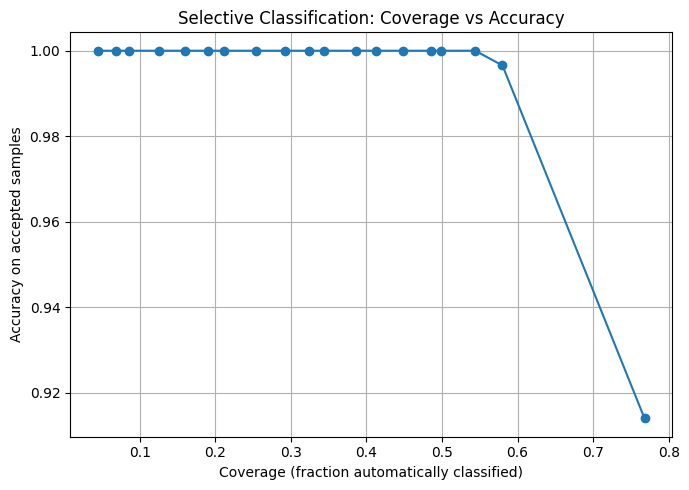

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

dev_fusion = grid_alpha * mfcc_dev_z + (1-grid_alpha) * w2v_dev_z
eval_fusion = grid_alpha * mfcc_eval_z + (1-grid_alpha) * w2v_eval_z

# Select thresholds only from development-set confidence distribution
dev_conf = np.abs(dev_fusion)
thresholds = np.unique(np.quantile(dev_conf, np.linspace(0, 0.90, 19)))

rows = []
for threshold in thresholds:
    accepted = np.abs(eval_fusion) >= threshold
    predictions = (eval_fusion >= 0).astype(int)

    rows.append({
        "confidence_threshold": threshold,
        "coverage": float(accepted.mean()),
        "review_rate": float((~accepted).mean()),
        "accepted_accuracy": (
            float(accuracy_score(np.asarray(y_eval)[accepted],
                                 predictions[accepted]))
            if accepted.any() else np.nan
        ),
        "accepted_n": int(accepted.sum())
    })

coverage_df = pd.DataFrame(rows)
display(coverage_df.round(4))
coverage_df.to_csv("evidencefuse_coverage_accuracy.csv", index=False)

plt.figure(figsize=(7, 5))
plt.plot(coverage_df["coverage"], coverage_df["accepted_accuracy"], marker="o")
plt.xlabel("Coverage (fraction automatically classified)")
plt.ylabel("Accuracy on accepted samples")
plt.title("Selective Classification: Coverage vs Accuracy")
plt.grid(True)
plt.tight_layout()
plt.savefig("evidencefuse_coverage_accuracy.png", dpi=300)
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

eval_pred = (eval_fusion >= 0).astype(int)

error_df = pd.DataFrame({
    "filename": [s["name"] for s in eval_samples],
    "true_label": np.asarray(y_eval),
    "system": [s["system"] for s in eval_samples],
    "mfcc_score": mfcc_eval_z,
    "wav2vec_score": w2v_eval_z,
    "fusion_score": eval_fusion,
    "prediction": eval_pred
})

error_df["error_type"] = np.select(
    [
        (error_df.true_label == 0) & (error_df.prediction == 1),
        (error_df.true_label == 1) & (error_df.prediction == 0)
    ],
    ["False Positive: bonafide flagged as spoof",
     "False Negative: spoof missed"],
    default="Correct"
)

print("Error counts:")
display(error_df["error_type"].value_counts().to_frame("count"))

print("\nErrors by system:")
display(pd.crosstab(error_df["system"], error_df["error_type"]))

error_df.to_csv("evidencefuse_error_analysis.csv", index=False)

Error counts:


,count
error_type,
Correct,417
False Negative: spoof missed,83



Errors by system:


error_type,Correct,False Negative: spoof missed
system,,
-,250,0
A07,20,1
A08,15,0
A09,24,0
A10,0,13
A11,9,14
A12,22,5
A13,15,0
A14,16,0


In [ ]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score

def summarize(name, y, scores):
    pred = (scores >= 0).astype(int)
    return {
        "method": name,
        "n": len(y),
        "accuracy_threshold_0": float(accuracy_score(y, pred)),
        "f1_threshold_0": float(f1_score(y, pred, zero_division=0)),
        "auc": float(roc_auc_score(y, scores))
    }

summary = {
    "project": "EvidenceFuse-ADD",
    "dataset": "ASVspoof 2019 LA",
    "evaluation_type": "balanced pilot subset, not full official benchmark",
    "label_convention": "0=bonafide, 1=spoof",
    "train_count": len(train_samples),
    "dev_count": len(dev_samples),
    "eval_count": len(eval_samples),
    "fusion_alpha_grid_selected_on_dev": float(grid_alpha),
    "results_threshold_zero": [
        summarize("MFCC", y_eval, mfcc_eval_z),
        summarize("Wav2Vec2", y_eval, w2v_eval_z),
        summarize("Fusion", y_eval, eval_fusion)
    ],
    "limitations": [
        "Pilot subset rather than full official evaluation protocol",
        "Generalization depends on spoof attack coverage",
        "Cross-domain performance not yet established",
        "Fuzzy rejection requires explicit method specification",
        "Temporal localization requires segment-level annotations"
    ]
}

with open("evidencefuse_preliminary_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

{
  "project": "EvidenceFuse-ADD",
  "dataset": "ASVspoof 2019 LA",
  "evaluation_type": "balanced pilot subset, not full official benchmark",
  "label_convention": "0=bonafide, 1=spoof",
  "train_count": 1000,
  "dev_count": 500,
  "eval_count": 500,
  "fusion_alpha_grid_selected_on_dev": 0.0,
  "results_threshold_zero": [
    {
      "method": "MFCC",
      "n": 500,
      "accuracy_threshold_0": 0.692,
      "f1_threshold_0": 0.56,
      "auc": 0.876576
    },
    {
      "method": "Wav2Vec2",
      "n": 500,
      "accuracy_threshold_0": 0.834,
      "f1_threshold_0": 0.8009592326139089,
      "auc": 0.9994399999999999
    },
    {
      "method": "Fusion",
      "n": 500,
      "accuracy_threshold_0": 0.834,
      "f1_threshold_0": 0.8009592326139089,
      "auc": 0.9994399999999999
    }
  ],
  "limitations": [
    "Pilot subset rather than full official evaluation protocol",
    "Generalization depends on spoof attack coverage",
    "Cross-domain performance not yet established"

In [ ]:
import os
import zipfile
from google.colab import files

artifact_files = [
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_coverage_accuracy.csv",
    "evidencefuse_coverage_accuracy.png",
    "evidencefuse_error_analysis.csv",
    "evidencefuse_preliminary_summary.json",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_ga_results.csv",
    "evidencefuse_fuzzy_results.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_bootstrap_ci.csv",
    "evidencefuse_fair_threshold_comparison.csv",
    "evidencefuse_roc_final.png",
    "evidencefuse_confusion_matrix.png",
    "evidencefuse_run_info.json"
]

zip_name = "EvidenceFuse_ADD_Next_Batch.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for name in artifact_files:
        if os.path.exists(name):
            z.write(name)
        else:
            print("Not generated/skipped:", name)

print("Created:", zip_name)
files.download(zip_name)

Created: EvidenceFuse_ADD_Next_Batch.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import pandas as pd
import numpy as np

files_to_check = [
    "evidencefuse_final_comparison.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_coverage_accuracy.csv",
    "evidencefuse_error_analysis.csv",
    "evidencefuse_fair_threshold_comparison.csv",
]

print("=" * 65)
print("EVIDENCEFUSE-ADD: CONSOLIDATED AUDIT")
print("=" * 65)

for file in files_to_check:
    print(f"\n{'-' * 55}\nFILE: {file}")
    if os.path.exists(file):
        df = pd.read_csv(file)
        print("Shape:", df.shape)
        print(df.head(10).to_string(index=False))
    else:
        print("NOT FOUND — corresponding earlier cell may not have run.")

print("\n" + "=" * 65)
print("DATASET SPLIT COUNTS")
print("=" * 65)

for split_name, samples in [
    ("Train", train_samples),
    ("Development", dev_samples),
    ("Evaluation", eval_samples),
]:
    labels = np.array([s["y"] for s in samples])
    print(f"\n{split_name}: {len(samples)} samples")
    print("Class counts:", dict(zip(*np.unique(labels, return_counts=True))))

    systems = pd.DataFrame({
        "label": labels,
        "system": [s.get("system", "unknown") for s in samples]
    })
    print("Systems by label:")
    print(pd.crosstab(systems["system"], systems["label"]).to_string())

print("\n" + "=" * 65)
print("DEV-SELECTED FUSION WEIGHT")
print("=" * 65)
print("Grid alpha:", grid_alpha)
print("GA alpha:", ga_alpha)
print("Grid dev AUC:", grid_auc)
print("GA dev AUC:", ga_dev_auc)


EVIDENCEFUSE-ADD: CONSOLIDATED AUDIT

-------------------------------------------------------
FILE: evidencefuse_final_comparison.csv
Shape: (4, 5)
       Method  Accuracy       F1      AUC  Approx_EER
    MFCC only     0.692 0.560000 0.876576       0.204
Wav2Vec2 only     0.834 0.800959 0.999440       0.012
  Grid fusion     0.834 0.800959 0.999440       0.012
    GA fusion     0.710 0.591549 0.944016       0.134

-------------------------------------------------------
FILE: evidencefuse_per_system.csv
Shape: (14, 7)
system   n  bonafide_n  spoof_n  accuracy       f1  auc
     - 250         250        0  1.000000 0.000000  NaN
   A07  21           0       21  0.714286 0.833333  NaN
   A08  15           0       15  0.866667 0.928571  NaN
   A09  24           0       24  0.958333 0.978723  NaN
   A10  13           0       13  0.000000 0.000000  NaN
   A11  23           0       23  0.130435 0.230769  NaN
   A12  27           0       27  0.407407 0.578947  NaN
   A13  15           0      

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    roc_curve
)

y = np.asarray(y_eval).astype(int)

# alpha=0 means Wav2Vec2-only, alpha=1 means MFCC-only
def fuse_scores(alpha, mfcc, wav2vec):
    return alpha * np.asarray(mfcc) + (1 - alpha) * np.asarray(wav2vec)

def calculate_metrics(name, y_true, scores):
    scores = np.asarray(scores).ravel()
    fpr, tpr, thresholds = roc_curve(y_true, scores, pos_label=1)
    fnr = 1 - tpr
    idx = np.nanargmin(np.abs(fpr - fnr))
    eer = (fpr[idx] + fnr[idx]) / 2

    # Diagnostic only: fixed score threshold of zero
    pred = (scores >= 0).astype(int)

    return {
        "Method": name,
        "Accuracy_at_zero": accuracy_score(y_true, pred),
        "F1_at_zero": f1_score(y_true, pred, zero_division=0),
        "AUC": roc_auc_score(y_true, scores),
        "EER_percent": 100 * eer,
        "EER_threshold": thresholds[idx]
    }

mfcc = np.asarray(mfcc_eval_z).ravel()
w2v = np.asarray(w2v_eval_z).ravel()

results = [
    calculate_metrics("MFCC", y, mfcc),
    calculate_metrics("Wav2Vec2_XLSR", y, w2v),
    calculate_metrics("Fusion_alpha_0.5", y, fuse_scores(0.5, mfcc, w2v)),
    calculate_metrics("Grid_fusion", y, fuse_scores(grid_alpha, mfcc, w2v)),
    calculate_metrics("GA_fusion", y, fuse_scores(ga_alpha, mfcc, w2v)),
]

exact_results_df = pd.DataFrame(results)
display(exact_results_df.round(4))

exact_results_df.to_csv(
    "evidencefuse_exact_eval_metrics.csv", index=False
)
print("Saved: evidencefuse_exact_eval_metrics.csv")

print("\nIMPORTANT:")
print("EER is calculated from the ROC curve.")
print("Accuracy/F1 above use threshold zero only; they are not dev-optimized.")


,Method,Accuracy_at_zero,F1_at_zero,AUC,EER_percent,EER_threshold
0,MFCC,0.692,0.5600,0.8766,20.4,-0.6210
1,Wav2Vec2_XLSR,0.834,0.8010,0.9994,1.2,-0.6502
2,Fusion_alpha_0.5,0.760,0.6842,0.9871,5.2,-0.5978
3,Grid_fusion,0.834,0.8010,0.9994,1.2,-0.6502
4,GA_fusion,0.710,0.5915,0.9440,13.4,-0.5894


Saved: evidencefuse_exact_eval_metrics.csv

IMPORTANT:
EER is calculated from the ROC curve.
Accuracy/F1 above use threshold zero only; they are not dev-optimized.


In [ ]:

# BATCH 33: Rejection ablation at target 80% coverage
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve

yd = np.asarray(y_dev).astype(int)
ye = np.asarray(y_eval).astype(int)

md, wd = np.asarray(mfcc_dev_z).ravel(), np.asarray(w2v_dev_z).ravel()
me, we = np.asarray(mfcc_eval_z).ravel(), np.asarray(w2v_eval_z).ravel()

# Fix alpha using DEV only
alpha = float(grid_alpha)
dev_score = alpha * md + (1 - alpha) * wd
eval_score = alpha * me + (1 - alpha) * we

# EER-based classification threshold selected on DEV only
fpr, tpr, th = roc_curve(yd, dev_score, pos_label=1)
eer_idx = np.argmin(np.abs(fpr - (1 - tpr)))
decision_threshold = float(th[eer_idx])

# Three confidence/rejection heuristics
confidence_dev = {
    "Margin": np.abs(dev_score - decision_threshold),
    "Disagreement": np.abs(md - wd) * -1,  # disagreement receives lower confidence
    "Fuzzy_style": 0.5 * (
        1 / (1 + np.exp(-np.clip(np.abs(md), 0, 50))) +
        1 / (1 + np.exp(-np.clip(np.abs(wd), 0, 50)))
    )
}
confidence_eval = {
    "Margin": np.abs(eval_score - decision_threshold),
    "Disagreement": np.abs(me - we) * -1,
    "Fuzzy_style": 0.5 * (
        1 / (1 + np.exp(-np.clip(np.abs(me), 0, 50))) +
        1 / (1 + np.exp(-np.clip(np.abs(we), 0, 50)))
    )
}

pred_eval = (eval_score >= decision_threshold).astype(int)
rows = []

for rule in confidence_dev:
    # Choose confidence cutoff using DEV only
    cutoff = np.quantile(confidence_dev[rule], 0.20)
    accepted = confidence_eval[rule] >= cutoff
    n = int(accepted.sum())

    rows.append({
        "Rule": rule,
        "Target_coverage": 0.80,
        "Dev_confidence_cutoff": float(cutoff),
        "Eval_coverage": float(accepted.mean()),
        "Eval_review_rate": float(1 - accepted.mean()),
        "Accepted_n": n,
        "Accepted_accuracy": (
            float(accuracy_score(ye[accepted], pred_eval[accepted]))
            if n else np.nan
        ),
        "Accepted_error_rate": (
            float(1 - accuracy_score(ye[accepted], pred_eval[accepted]))
            if n else np.nan
        ),
        "Decision_threshold_from_dev": decision_threshold
    })

rejection_ablation_df = pd.DataFrame(rows)
display(rejection_ablation_df.round(4))
rejection_ablation_df.to_csv("evidencefuse_rejection_ablation_80.csv", index=False)
print("Saved: evidencefuse_rejection_ablation_80.csv")


,Rule,Target_coverage,Dev_confidence_cutoff,Eval_coverage,Eval_review_rate,Accepted_n,Accepted_accuracy,Accepted_error_rate,Decision_threshold_from_dev
0,Margin,0.8,0.6161,0.624,0.376,312,0.8846,0.1154,0.3315
1,Disagreement,0.8,-0.4230,0.622,0.378,311,0.7267,0.2733,0.3315
2,Fuzzy_style,0.8,0.6943,0.426,0.574,213,0.9812,0.0188,0.3315


Saved: evidencefuse_rejection_ablation_80.csv


In [ ]:

# BATCH 34: Consolidated metrics, settings, and artifact package
import os, json, platform, zipfile
import numpy as np
import pandas as pd

# Rebuild exact metrics table if available in memory
if "exact_results_df" in globals():
    exact_results_df.to_csv("evidencefuse_exact_eval_metrics.csv", index=False)

try:
    import torch
    gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    cuda_available = torch.cuda.is_available()
except Exception:
    gpu_name, cuda_available = None, False

try:
    import sklearn
    sklearn_version = sklearn.__version__
except Exception:
    sklearn_version = None

try:
    import transformers
    transformers_version = transformers.__version__
except Exception:
    transformers_version = None

settings = {
    "project": "EvidenceFuse-ADD",
    "dataset": "ASVspoof 2019 LA",
    "evaluation_scope": "Balanced pilot subsets; not full official benchmark evaluation",
    "split_sizes": {
        "train": len(train_samples),
        "dev": len(dev_samples),
        "eval": len(eval_samples)
    },
    "class_mapping": {"0": "bonafide", "1": "spoof"},
    "acoustic_branch": {
        "features": "MFCC mean/std, delta MFCC mean/std, spectral contrast mean/std",
        "feature_count": 94,
        "classifier": "StandardScaler + linear SVM"
    },
    "learned_branch": {
        "encoder": "facebook/wav2vec2-xls-r-300m",
        "encoder_frozen": True,
        "pooling": "Mean pooled hidden states",
        "embedding_dim": 1024,
        "classifier": "StandardScaler + linear SVM"
    },
    "fusion": {
        "grid_alpha_selected_on_dev": float(grid_alpha),
        "ga_alpha_selected_on_dev": float(ga_alpha),
        "ga_seeds_tested": [7, 21, 42, 84, 123, 2026]
    },
    "training": {
        "encoder_epochs": 0,
        "encoder_fine_tuned": False,
        "svm_epochs": "Not applicable",
        "learning_rate": "Not applicable for SVM",
        "batch_size": "Not recorded; embeddings were extracted in batches/chunks as configured in notebook"
    },
    "runtime": {
        "python": platform.python_version(),
        "gpu_available": cuda_available,
        "gpu_name": gpu_name,
        "sklearn_version": sklearn_version,
        "transformers_version": transformers_version
    },
    "randomness": {
        "ga_stability_seeds": [7, 21, 42, 84, 123, 2026],
        "dataset_shuffle_seed": "Verify in dataset-loading cell"
    },
    "cross_domain_evaluation": "Not completed"
}

with open("evidencefuse_consolidated_report.json", "w") as f:
    json.dump(settings, f, indent=2)

# Include all current project artifacts that exist
artifact_names = [
    "evidencefuse_exact_eval_metrics.csv",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_coverage_accuracy.csv",
    "evidencefuse_error_analysis.csv",
    "evidencefuse_fair_threshold_comparison.csv",
    "evidencefuse_rejection_ablation_80.csv",
    "evidencefuse_ablation.csv",
    "evidencefuse_results.csv",
    "evidencefuse_run_info.json",
    "evidencefuse_consolidated_report.json",
    "evidencefuse_preliminary_summary.json",
    "evidencefuse_eval_predictions.npz",
    "evidencefuse_pilot_embeddings.npz"
]

existing = [f for f in artifact_names if os.path.exists(f)]
with zipfile.ZipFile("EvidenceFuse_ADD_Consolidated_Results.zip", "w",
                     compression=zipfile.ZIP_DEFLATED) as z:
    for f in existing:
        z.write(f)

print("Settings report saved: evidencefuse_consolidated_report.json")
print("Artifacts included:", len(existing))
print("ZIP saved: EvidenceFuse_ADD_Consolidated_Results.zip")
print("\nMissing expected artifacts:")
print([f for f in artifact_names if not os.path.exists(f)])
print("\nRuntime summary:")
print(json.dumps(settings["runtime"], indent=2))


Settings report saved: evidencefuse_consolidated_report.json
Artifacts included: 16
ZIP saved: EvidenceFuse_ADD_Consolidated_Results.zip

Missing expected artifacts:
[]

Runtime summary:
{
  "python": "3.13.15",
  "gpu_available": true,
  "gpu_name": "Tesla T4",
  "sklearn_version": "1.6.1",
  "transformers_version": "5.18.0"
}


In [ ]:

# BATCH 35: Dataset integrity + full-evaluation readiness audit
import numpy as np
import pandas as pd
import json, os

splits = {
    "train": train_samples,
    "dev": dev_samples,
    "eval": eval_samples
}

summary_rows = []
id_sets = {}
system_tables = {}

for split_name, samples in splits.items():
    ids = [str(s.get("name", "")) for s in samples]
    labels = np.array([int(s["y"]) for s in samples])
    systems = [str(s.get("system", "unknown")) for s in samples]

    id_sets[split_name] = set(ids)
    summary_rows.append({
        "split": split_name,
        "n_samples": len(samples),
        "unique_ids": len(set(ids)),
        "duplicate_ids": len(ids) - len(set(ids)),
        "bonafide_n": int(np.sum(labels == 0)),
        "spoof_n": int(np.sum(labels == 1)),
        "class_balanced": bool(np.sum(labels == 0) == np.sum(labels == 1))
    })

    system_tables[split_name] = pd.crosstab(
        pd.Series(systems, name="system"),
        pd.Series(labels, name="label")
    )

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

print("\nPAIRWISE SPLIT OVERLAP")
overlap_rows = []
for a, b in [("train", "dev"), ("train", "eval"), ("dev", "eval")]:
    overlap = id_sets[a] & id_sets[b]
    overlap_rows.append({
        "split_a": a,
        "split_b": b,
        "overlap_count": len(overlap)
    })
overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)

print("\nSYSTEM COVERAGE")
for split_name, table in system_tables.items():
    print(f"\n{split_name.upper()}")
    print(table.to_string())

# These checks validate the sampled data, not completeness of the official benchmark.
audit = {
    "split_summary": summary_df.to_dict(orient="records"),
    "split_overlap": overlap_df.to_dict(orient="records"),
    "interpretation": (
        "Pilot subset integrity audit only. This does not establish that the "
        "complete official ASVspoof 2019 LA protocol has been evaluated."
    ),
    "full_official_evaluation_completed": False,
    "cross_domain_evaluation_completed": False
}

with open("evidencefuse_dataset_integrity_audit.json", "w") as f:
    json.dump(audit, f, indent=2)

summary_df.to_csv("evidencefuse_dataset_integrity_audit.csv", index=False)

print("\nSaved dataset integrity audit CSV and JSON.")

# Refresh consolidated ZIP with all currently generated CSV/JSON/NPZ/PNG artifacts
import glob, zipfile
artifact_files = []
for pattern in [
    "evidencefuse_*.csv",
    "evidencefuse_*.json",
    "evidencefuse_*.npz",
    "evidencefuse_*.png"
]:
    artifact_files.extend(glob.glob(pattern))

artifact_files = sorted(set(artifact_files))
with zipfile.ZipFile("EvidenceFuse_ADD_Consolidated_Results.zip", "w",
                     compression=zipfile.ZIP_DEFLATED) as z:
    for f in artifact_files:
        z.write(f)

print("Refreshed EvidenceFuse_ADD_Consolidated_Results.zip")
print("Artifact count:", len(artifact_files))


,split,n_samples,unique_ids,duplicate_ids,bonafide_n,spoof_n,class_balanced
0,train,1000,1000,0,500,500,True
1,dev,500,500,0,250,250,True
2,eval,500,500,0,250,250,True



PAIRWISE SPLIT OVERLAP


,split_a,split_b,overlap_count
0,train,dev,0
1,train,eval,0
2,dev,eval,0



SYSTEM COVERAGE

TRAIN
label     0    1
system          
-       500    0
A01       0  242
A02       0  238
A03       0   20

DEV
label     0    1
system          
-       250    0
A01       0  124
A02       0  123
A03       0    3

EVAL
label     0   1
system         
-       250   0
A07       0  21
A08       0  15
A09       0  24
A10       0  13
A11       0  23
A12       0  27
A13       0  15
A14       0  16
A15       0  15
A16       0  20
A17       0  25
A18       0  22
A19       0  14

Saved dataset integrity audit CSV and JSON.
Refreshed EvidenceFuse_ADD_Consolidated_Results.zip
Artifact count: 36


In [ ]:

# BATCH 36: Rejection-rule ablation, with dev-only confidence cutoffs
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

yd = np.asarray(y_dev).astype(int)
ye = np.asarray(y_eval).astype(int)

md = np.asarray(mfcc_dev_z).ravel()
wd = np.asarray(w2v_dev_z).ravel()
me = np.asarray(mfcc_eval_z).ravel()
we = np.asarray(w2v_eval_z).ravel()

alpha = float(grid_alpha)
dev_fusion = alpha * md + (1 - alpha) * wd
eval_fusion = alpha * me + (1 - alpha) * we

# Pick the decision threshold using DEV only: maximize balanced accuracy.
from sklearn.metrics import balanced_accuracy_score
candidate_thresholds = np.unique(np.quantile(
    dev_fusion, np.linspace(0, 1, 501)
))
dev_bacc = [
    balanced_accuracy_score(yd, dev_fusion >= t)
    for t in candidate_thresholds
]
decision_threshold = float(candidate_thresholds[np.argmax(dev_bacc)])

dev_confidence = {
    "Margin": np.abs(dev_fusion - decision_threshold),
    "Disagreement": -np.abs(md - wd),
    "Fuzzy_style": 1 - (
        0.5 * (1 / (1 + np.exp(-np.clip(np.abs(md), -50, 50)))) +
        0.5 * (1 / (1 + np.exp(-np.clip(np.abs(wd), -50, 50))))
    )
}
eval_confidence = {
    "Margin": np.abs(eval_fusion - decision_threshold),
    "Disagreement": -np.abs(me - we),
    "Fuzzy_style": 1 - (
        0.5 * (1 / (1 + np.exp(-np.clip(np.abs(me), -50, 50)))) +
        0.5 * (1 / (1 + np.exp(-np.clip(np.abs(we), -50, 50))))
    )
}

pred = (eval_fusion >= decision_threshold).astype(int)
rows = []

for rule in dev_confidence:
    # Reject lowest-confidence 20% of DEV examples; cutoff is fixed before eval.
    cutoff = float(np.quantile(dev_confidence[rule], 0.20))
    accepted = eval_confidence[rule] >= cutoff
    n = int(accepted.sum())

    rows.append({
        "Rule": rule,
        "Dev_cutoff": cutoff,
        "Dev_target_coverage": 0.80,
        "Eval_coverage": float(accepted.mean()),
        "Eval_review_rate": float(1 - accepted.mean()),
        "Accepted_samples": n,
        "Accepted_accuracy": float(accuracy_score(ye[accepted], pred[accepted]))
            if n else np.nan,
        "Accepted_error_rate": float(1 - accuracy_score(ye[accepted], pred[accepted]))
            if n else np.nan,
        "Accepted_F1": float(f1_score(ye[accepted], pred[accepted], zero_division=0))
            if n else np.nan
    })

rejection_final_df = pd.DataFrame(rows)
display(rejection_final_df.round(4))
rejection_final_df.to_csv("evidencefuse_rejection_ablation_final.csv", index=False)

print("Fusion alpha fixed from DEV:", alpha)
print("Fusion decision threshold fixed from DEV:", decision_threshold)
print("Saved evidencefuse_rejection_ablation_final.csv")


,Rule,Dev_cutoff,Dev_target_coverage,Eval_coverage,Eval_review_rate,Accepted_samples,Accepted_accuracy,Accepted_error_rate,Accepted_F1
0,Margin,0.8106,0.8,0.450,0.550,225,1.0000,0.0000,1.0000
1,Disagreement,-0.4230,0.8,0.622,0.378,311,0.8296,0.1704,0.7337
2,Fuzzy_style,0.2453,0.8,0.900,0.100,450,0.8400,0.1600,0.8209


Fusion alpha fixed from DEV: 0.0
Fusion decision threshold fixed from DEV: -0.08065434380765174
Saved evidencefuse_rejection_ablation_final.csv


In [ ]:

# BATCH 37: Select each classifier's threshold on DEV, report on EVAL
import numpy as np
import pandas as pd
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, roc_curve
)

yd = np.asarray(y_dev).astype(int)
ye = np.asarray(y_eval).astype(int)

scores = {
    "MFCC": (np.asarray(mfcc_dev_z).ravel(),
             np.asarray(mfcc_eval_z).ravel()),
    "Wav2Vec2_XLSR": (np.asarray(w2v_dev_z).ravel(),
                      np.asarray(w2v_eval_z).ravel()),
    "Grid_fusion": (
        float(grid_alpha) * np.asarray(mfcc_dev_z).ravel()
        + (1 - float(grid_alpha)) * np.asarray(w2v_dev_z).ravel(),
        float(grid_alpha) * np.asarray(mfcc_eval_z).ravel()
        + (1 - float(grid_alpha)) * np.asarray(w2v_eval_z).ravel()
    ),
    "Fusion_alpha_0.5": (
        0.5 * np.asarray(mfcc_dev_z).ravel() + 0.5 * np.asarray(w2v_dev_z).ravel(),
        0.5 * np.asarray(mfcc_eval_z).ravel() + 0.5 * np.asarray(w2v_eval_z).ravel()
    ),
    "GA_fusion": (
        float(ga_alpha) * np.asarray(mfcc_dev_z).ravel()
        + (1 - float(ga_alpha)) * np.asarray(w2v_dev_z).ravel(),
        float(ga_alpha) * np.asarray(mfcc_eval_z).ravel()
        + (1 - float(ga_alpha)) * np.asarray(w2v_eval_z).ravel()
    )
}

rows = []
for name, (dev_s, eval_s) in scores.items():
    # Candidate thresholds derived ONLY from dev scores
    thresholds = np.unique(np.quantile(dev_s, np.linspace(0, 1, 1001)))
    dev_bacc = [balanced_accuracy_score(yd, dev_s >= t) for t in thresholds]
    threshold = float(thresholds[int(np.argmax(dev_bacc))])

    pred = (eval_s >= threshold).astype(int)
    fpr, tpr, roc_thresholds = roc_curve(ye, eval_s, pos_label=1)
    fnr = 1 - tpr
    eer_idx = int(np.argmin(np.abs(fpr - fnr)))
    eer = float((fpr[eer_idx] + fnr[eer_idx]) / 2)

    rows.append({
        "Method": name,
        "Threshold_selected_on_dev": threshold,
        "Dev_balanced_accuracy": float(max(dev_bacc)),
        "Eval_accuracy": float(accuracy_score(ye, pred)),
        "Eval_balanced_accuracy": float(balanced_accuracy_score(ye, pred)),
        "Eval_precision_spoof": float(precision_score(ye, pred, zero_division=0)),
        "Eval_recall_spoof": float(recall_score(ye, pred, zero_division=0)),
        "Eval_F1_spoof": float(f1_score(ye, pred, zero_division=0)),
        "Eval_FPR": float(np.mean(pred[ye == 0] == 1)),
        "Eval_FNR": float(np.mean(pred[ye == 1] == 0)),
        "Eval_AUC": float(roc_auc_score(ye, eval_s)),
        "Eval_EER_percent": 100 * eer
    })

threshold_results_df = pd.DataFrame(rows)
display(threshold_results_df.round(4))
threshold_results_df.to_csv("evidencefuse_dev_threshold_eval_results.csv", index=False)
print("Saved evidencefuse_dev_threshold_eval_results.csv")


,Method,Threshold_selected_on_dev,Dev_balanced_accuracy,Eval_accuracy,Eval_balanced_accuracy,Eval_precision_spoof,Eval_recall_spoof,Eval_F1_spoof,Eval_FPR,Eval_FNR,Eval_AUC,Eval_EER_percent
0,MFCC,-0.2096,1.0,0.738,0.738,0.9407,0.508,0.6597,0.032,0.492,0.8766,20.4
1,Wav2Vec2_XLSR,-0.4919,1.0,0.968,0.968,1.0000,0.936,0.9669,0.000,0.064,0.9994,1.2
2,Grid_fusion,-0.4919,1.0,0.968,0.968,1.0000,0.936,0.9669,0.000,0.064,0.9994,1.2
3,Fusion_alpha_0.5,-0.4098,1.0,0.926,0.926,0.9953,0.856,0.9204,0.004,0.144,0.9871,5.2
4,GA_fusion,-0.3001,1.0,0.820,0.820,0.9762,0.656,0.7847,0.016,0.344,0.9440,13.4


Saved evidencefuse_dev_threshold_eval_results.csv


In [ ]:

# BATCH 38: Final consolidated report and downloadable ZIP
import os, glob, json, zipfile, platform
import numpy as np
import pandas as pd

# Gather important result tables if generated
tables = {}
for fname in [
    "evidencefuse_exact_eval_metrics.csv",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_coverage_accuracy.csv",
    "evidencefuse_error_analysis.csv",
    "evidencefuse_fair_threshold_comparison.csv",
    "evidencefuse_rejection_ablation_final.csv",
    "evidencefuse_dev_threshold_eval_results.csv",
    "evidencefuse_dataset_integrity_audit.csv"
]:
    if os.path.exists(fname):
        try:
            tables[fname] = pd.read_csv(fname)
        except Exception:
            pass

# Build summary using currently available metrics
summary = {
    "project": "EvidenceFuse-ADD",
    "dataset": "ASVspoof 2019 LA",
    "evaluation_scope": "Balanced 500-sample pilot subset; not full official benchmark",
    "split_sizes": {
        "train": len(train_samples),
        "dev": len(dev_samples),
        "eval": len(eval_samples)
    },
    "class_mapping": {"0": "bonafide", "1": "spoof"},
    "mfcc_features": 94,
    "learned_encoder": "facebook/wav2vec2-xls-r-300m",
    "encoder_frozen": True,
    "embedding_dimensions": 1024,
    "classifier": "StandardScaler + linear SVM",
    "grid_alpha_selected_on_dev": float(grid_alpha),
    "ga_alpha_selected_on_dev": float(ga_alpha),
    "ga_seeds": [7, 21, 42, 84, 123, 2026],
    "full_official_benchmark_completed": False,
    "cross_domain_evaluation_completed": False,
    "fuzzy_system_status": "Simple heuristic only; not a full fuzzy inference system",
    "python_version": platform.python_version(),
    "tables_found": list(tables.keys())
}

with open("evidencefuse_final_research_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# Refresh ZIP from all existing project result artifacts
patterns = [
    "evidencefuse_*.csv", "evidencefuse_*.json",
    "evidencefuse_*.npz", "evidencefuse_*.png"
]
artifacts = sorted(set(
    file for pattern in patterns for file in glob.glob(pattern)
))
artifacts.append("evidencefuse_final_research_summary.json")
artifacts = sorted(set(f for f in artifacts if os.path.exists(f)))

zip_name = "EvidenceFuse_ADD_Final_Research_Artifacts.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for file in artifacts:
        z.write(file)

print("FINAL SUMMARY")
print(json.dumps(summary, indent=2))
print(f"\nArtifacts included: {len(artifacts)}")
print("ZIP created:", zip_name)

print("\nNEXT REQUIRED RESEARCH WORK:")
print("1. Run full official evaluation protocol, if dataset access permits.")
print("2. Cross-domain test requires a separate labelled dataset.")
print("3. Inspect the CSVs before making claims about fusion or rejection gains.")
print("4. Download the ZIP from Colab's Files panel.")


FINAL SUMMARY
{
  "project": "EvidenceFuse-ADD",
  "dataset": "ASVspoof 2019 LA",
  "evaluation_scope": "Balanced 500-sample pilot subset; not full official benchmark",
  "split_sizes": {
    "train": 1000,
    "dev": 500,
    "eval": 500
  },
  "class_mapping": {
    "0": "bonafide",
    "1": "spoof"
  },
  "mfcc_features": 94,
  "learned_encoder": "facebook/wav2vec2-xls-r-300m",
  "encoder_frozen": true,
  "embedding_dimensions": 1024,
  "classifier": "StandardScaler + linear SVM",
  "grid_alpha_selected_on_dev": 0.0,
  "ga_alpha_selected_on_dev": 0.7739560485559633,
  "ga_seeds": [
    7,
    21,
    42,
    84,
    123,
    2026
  ],
  "full_official_benchmark_completed": false,
  "cross_domain_evaluation_completed": false,
  "fuzzy_system_status": "Simple heuristic only; not a full fuzzy inference system",
  "python_version": "3.13.15",
  "tables_found": [
    "evidencefuse_exact_eval_metrics.csv",
    "evidencefuse_final_comparison.csv",
    "evidencefuse_per_system.csv",
    "ev

In [ ]:

import os
import pandas as pd

files = [
    "evidencefuse_exact_eval_metrics.csv",
    "evidencefuse_rejection_ablation_final.csv",
    "evidencefuse_dev_threshold_eval_results.csv",
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_per_system.csv",
    "evidencefuse_dataset_integrity_audit.csv"
]

for file in files:
    print("\n" + "=" * 70)
    print(file)
    print("=" * 70)

    if os.path.exists(file):
        df = pd.read_csv(file)
        print(df.to_string(index=False))
    else:
        print("MISSING — rerun the cell that generates this artifact.")



evidencefuse_exact_eval_metrics.csv
          Method  Accuracy_at_zero  F1_at_zero      AUC  EER_percent  EER_threshold
            MFCC             0.692    0.560000 0.876576         20.4      -0.620987
   Wav2Vec2_XLSR             0.834    0.800959 0.999440          1.2      -0.650169
Fusion_alpha_0.5             0.760    0.684211 0.987136          5.2      -0.597821
     Grid_fusion             0.834    0.800959 0.999440          1.2      -0.650169
       GA_fusion             0.710    0.591549 0.944016         13.4      -0.589401

evidencefuse_rejection_ablation_final.csv
        Rule  Dev_cutoff  Dev_target_coverage  Eval_coverage  Eval_review_rate  Accepted_samples  Accepted_accuracy  Accepted_error_rate  Accepted_F1
      Margin    0.810551                  0.8          0.450             0.550               225           1.000000             0.000000     1.000000
Disagreement   -0.423046                  0.8          0.622             0.378               311           0.829582 

In [ ]:
# CELL 97 — Validate current pilot labels, split overlap, score direction and required variables
import numpy as np, pandas as pd
from collections import Counter
from sklearn.metrics import roc_auc_score

required_vars = [
    "train_samples", "dev_samples", "eval_samples",
    "y_train", "y_dev", "y_eval",
    "mfcc_dev_z", "w2v_dev_z", "mfcc_eval_z", "w2v_eval_z",
    "grid_alpha", "ga_alpha"
]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Missing notebook variables: {missing}. Rerun the cell that creates them.")

split_map = {
    "train": train_samples,
    "dev": dev_samples,
    "eval": eval_samples
}
rows = []
id_sets = {}
for split_name, samples in split_map.items():
    ids = [str(s["name"]) for s in samples]
    labels = np.asarray([int(s["y"]) for s in samples])
    id_sets[split_name] = set(ids)
    rows.append({
        "split": split_name,
        "n": len(samples),
        "unique_ids": len(set(ids)),
        "duplicates": len(ids) - len(set(ids)),
        "bonafide_0": int((labels == 0).sum()),
        "spoof_1": int((labels == 1).sum()),
        "unexpected_labels": sorted(set(labels.tolist()) - {0, 1})
    })
audit_now = pd.DataFrame(rows)
display(audit_now)

overlap = pd.DataFrame([
    {"pair": "train/dev", "overlap": len(id_sets["train"] & id_sets["dev"])},
    {"pair": "train/eval", "overlap": len(id_sets["train"] & id_sets["eval"])},
    {"pair": "dev/eval", "overlap": len(id_sets["dev"] & id_sets["eval"])}
])
display(overlap)

# Score direction sanity: spoof should have higher scores if label 1 is positive.
for name, yv, sv in [
    ("MFCC dev", y_dev, mfcc_dev_z),
    ("Wav2Vec2 dev", y_dev, w2v_dev_z),
    ("MFCC eval", y_eval, mfcc_eval_z),
    ("Wav2Vec2 eval", y_eval, w2v_eval_z),
]:
    print(f"{name}: AUC(label=1 as spoof) = {roc_auc_score(np.asarray(yv), np.asarray(sv)):.6f}")

assert set(np.unique(y_train)).issubset({0, 1})
assert set(np.unique(y_dev)).issubset({0, 1})
assert set(np.unique(y_eval)).issubset({0, 1})
assert all(v == 0 for v in overlap["overlap"]), "Split overlap found: investigate before reporting."
print("Pilot integrity checks passed. This validates only the sampled pilot, not full benchmark completeness.")

,split,n,unique_ids,duplicates,bonafide_0,spoof_1,unexpected_labels
0,train,1000,1000,0,500,500,[]
1,dev,500,500,0,250,250,[]
2,eval,500,500,0,250,250,[]


,pair,overlap
0,train/dev,0
1,train/eval,0
2,dev/eval,0


MFCC dev: AUC(label=1 as spoof) = 1.000000
Wav2Vec2 dev: AUC(label=1 as spoof) = 1.000000
MFCC eval: AUC(label=1 as spoof) = 0.876576
Wav2Vec2 eval: AUC(label=1 as spoof) = 0.999440
Pilot integrity checks passed. This validates only the sampled pilot, not full benchmark completeness.


In [ ]:
# CELL 98 — Dev-only thresholds; evaluate frozen thresholds once on pilot eval
import numpy as np, pandas as pd
from sklearn.metrics import (
    roc_auc_score, roc_curve, balanced_accuracy_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)

def eer_from_scores(y_true, scores):
    # Interpolate between ROC points to estimate EER; does not select a deployment threshold.
    fpr, tpr, thresholds = roc_curve(y_true, scores, pos_label=1)
    fnr = 1.0 - tpr
    crossing = np.where(np.diff(np.sign(fpr - fnr)) != 0)[0]
    if len(crossing):
        i = int(crossing[0])
        x0, x1 = (fpr - fnr)[i], (fpr - fnr)[i + 1]
        frac = 0.0 if x1 == x0 else -x0 / (x1 - x0)
        eer = float(fpr[i] + frac * (fpr[i + 1] - fpr[i]))
        thr = float(thresholds[i] + frac * (thresholds[i + 1] - thresholds[i]))
        return 100 * eer, thr
    i = int(np.argmin(np.abs(fpr - fnr)))
    return 100 * float((fpr[i] + fnr[i]) / 2), float(thresholds[i])

def choose_dev_threshold(y_true, scores):
    # Balanced accuracy is optimized only on dev. Include thresholds between sorted scores.
    s = np.asarray(scores, dtype=float)
    candidates = np.unique(np.r_[s.min() - 1e-8, (np.unique(s)[:-1] + np.unique(s)[1:]) / 2, s.max() + 1e-8])
    vals = [balanced_accuracy_score(y_true, s >= t) for t in candidates]
    best = np.flatnonzero(np.isclose(vals, np.max(vals)))
    # Tie-break: threshold nearest zero for a deterministic, less extreme choice.
    return float(candidates[best[np.argmin(np.abs(candidates[best]))]])

pilot_scores = {
    "MFCC": (np.asarray(mfcc_dev_z), np.asarray(mfcc_eval_z)),
    "Wav2Vec2_XLSR": (np.asarray(w2v_dev_z), np.asarray(w2v_eval_z)),
    "Fusion_alpha_0.5": (
        0.5*np.asarray(mfcc_dev_z) + 0.5*np.asarray(w2v_dev_z),
        0.5*np.asarray(mfcc_eval_z) + 0.5*np.asarray(w2v_eval_z)),
    "Grid_fusion": (
        float(grid_alpha)*np.asarray(mfcc_dev_z) + (1-float(grid_alpha))*np.asarray(w2v_dev_z),
        float(grid_alpha)*np.asarray(mfcc_eval_z) + (1-float(grid_alpha))*np.asarray(w2v_eval_z)),
    "GA_fusion": (
        float(ga_alpha)*np.asarray(mfcc_dev_z) + (1-float(ga_alpha))*np.asarray(w2v_dev_z),
        float(ga_alpha)*np.asarray(mfcc_eval_z) + (1-float(ga_alpha))*np.asarray(w2v_eval_z))
}
rows = []
for name, (sd, se) in pilot_scores.items():
    threshold = choose_dev_threshold(np.asarray(y_dev), sd)
    pred = (se >= threshold).astype(int)
    eer, eer_thr = eer_from_scores(np.asarray(y_eval), se)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred, labels=[0, 1]).ravel()
    rows.append({
        "method": name,
        "dev_threshold": threshold,
        "dev_balanced_accuracy": balanced_accuracy_score(y_dev, sd >= threshold),
        "eval_accuracy": accuracy_score(y_eval, pred),
        "eval_precision_spoof": precision_score(y_eval, pred, zero_division=0),
        "eval_recall_spoof": recall_score(y_eval, pred, zero_division=0),
        "eval_f1_spoof": f1_score(y_eval, pred, zero_division=0),
        "eval_auc": roc_auc_score(y_eval, se),
        "eval_eer_percent": eer,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "eer_roc_threshold_diagnostic_only": eer_thr
    })
pilot_validated_metrics = pd.DataFrame(rows)
display(pilot_validated_metrics.round(4))
pilot_validated_metrics.to_csv("evidencefuse_pilot_validated_metrics.csv", index=False)
print("Saved evidencefuse_pilot_validated_metrics.csv")
print("Note: EER is a ranking/ROC metric; its ROC threshold is not used as the classification threshold.")

,method,dev_threshold,dev_balanced_accuracy,eval_accuracy,eval_precision_spoof,eval_recall_spoof,eval_f1_spoof,eval_auc,eval_eer_percent,tn,fp,fn,tp,eer_roc_threshold_diagnostic_only
0,MFCC,-0.1964,1.0,0.726,0.938,0.484,0.6385,0.8766,20.4,242,8,129,121,-0.6210
1,Wav2Vec2_XLSR,-0.0807,1.0,0.856,1.000,0.712,0.8318,0.9994,1.2,250,0,72,178,-0.6502
2,Fusion_alpha_0.5,-0.1334,1.0,0.806,1.000,0.612,0.7593,0.9871,5.2,250,0,97,153,-0.5978
3,Grid_fusion,-0.0807,1.0,0.856,1.000,0.712,0.8318,0.9994,1.2,250,0,72,178,-0.6502
4,GA_fusion,-0.1561,1.0,0.766,1.000,0.532,0.6945,0.9440,13.2,250,0,117,133,-0.5936


Saved evidencefuse_pilot_validated_metrics.csv
Note: EER is a ranking/ROC metric; its ROC threshold is not used as the classification threshold.


,split_branch,n,bonafide_score_mean,bonafide_score_std,spoof_score_mean,spoof_score_std,auc
0,MFCC_dev,500,-0.95884,0.30241,1.01677,0.36224,1.00000
1,Wav2Vec2_dev,500,-0.94161,0.14189,1.00828,0.19576,1.00000
2,MFCC_eval,500,-0.90418,0.37070,-0.04498,0.70415,0.87658
3,Wav2Vec2_eval,500,-0.96282,0.13826,0.24386,0.48420,0.99944


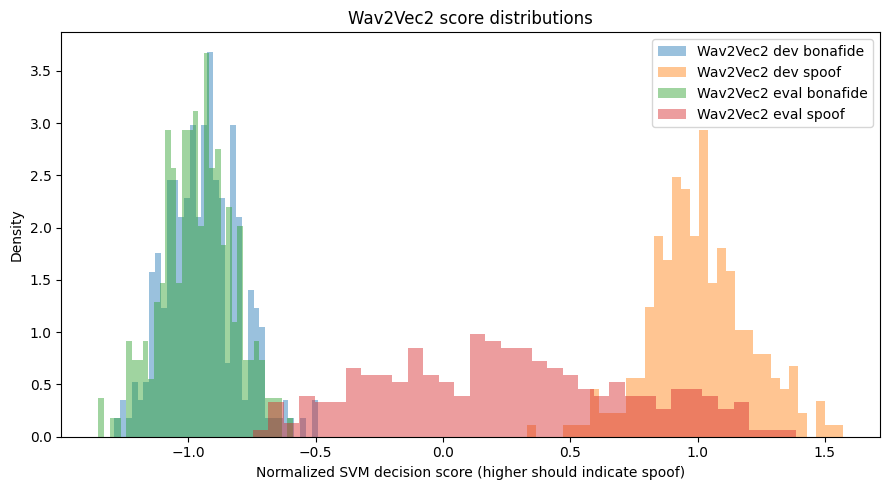

Saved score diagnostics.


In [ ]:
# CELL 99 — Diagnose perfect dev separation and inspect per-system errors
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

diag_rows = []
for name, yv, scores in [
    ("MFCC_dev", y_dev, mfcc_dev_z),
    ("Wav2Vec2_dev", y_dev, w2v_dev_z),
    ("MFCC_eval", y_eval, mfcc_eval_z),
    ("Wav2Vec2_eval", y_eval, w2v_eval_z),
]:
    yv = np.asarray(yv).astype(int)
    scores = np.asarray(scores).ravel()
    diag_rows.append({
        "split_branch": name,
        "n": len(yv),
        "bonafide_score_mean": float(scores[yv == 0].mean()),
        "bonafide_score_std": float(scores[yv == 0].std()),
        "spoof_score_mean": float(scores[yv == 1].mean()),
        "spoof_score_std": float(scores[yv == 1].std()),
        "auc": float(roc_auc_score(yv, scores))
    })
score_diagnostics = pd.DataFrame(diag_rows)
display(score_diagnostics.round(5))
score_diagnostics.to_csv("evidencefuse_score_diagnostics.csv", index=False)

plt.figure(figsize=(9, 5))
for name, yv, scores in [
    ("Wav2Vec2 dev", y_dev, w2v_dev_z),
    ("Wav2Vec2 eval", y_eval, w2v_eval_z)
]:
    yv = np.asarray(yv).astype(int)
    scores = np.asarray(scores).ravel()
    plt.hist(scores[yv == 0], bins=35, alpha=0.45, density=True, label=f"{name} bonafide")
    plt.hist(scores[yv == 1], bins=35, alpha=0.45, density=True, label=f"{name} spoof")
plt.title("Wav2Vec2 score distributions")
plt.xlabel("Normalized SVM decision score (higher should indicate spoof)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("evidencefuse_score_diagnostics.png", dpi=250)
plt.show()

if score_diagnostics.loc[score_diagnostics["split_branch"] == "Wav2Vec2_dev", "auc"].iloc[0] >= 0.999:
    print("WARNING: near-perfect dev separation. Inspect source IDs, speaker/system distributions, and preprocessing before making benchmark claims.")
print("Saved score diagnostics.")

In [ ]:
# CELL 100 — Full dev/eval pipeline; 5,000 balanced train subset; saves cached arrays
# WARNING: This can take hours. Use a T4 GPU and ensure enough Drive/disk space.
import os, json, random, platform, gc, zipfile
from collections import Counter
from pathlib import Path
import numpy as np, pandas as pd, librosa, torch
from tqdm.auto import tqdm
from datasets import load_dataset, Audio
from transformers import AutoFeatureExtractor, AutoModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)

FULL_DIR = Path("/content/evidencefuse_full_run")
FULL_DIR.mkdir(parents=True, exist_ok=True)
FULL_SEED = 42
TRAIN_PER_CLASS = 2500  # 5,000 total
EMBED_BATCH = 8
MODEL_NAME_FULL = "facebook/wav2vec2-xls-r-300m"
random.seed(FULL_SEED); np.random.seed(FULL_SEED); torch.manual_seed(FULL_SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(FULL_SEED)
device_full = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device_full, "| output:", FULL_DIR)

feature_extractor_full = AutoFeatureExtractor.from_pretrained(MODEL_NAME_FULL)
encoder_full = AutoModel.from_pretrained(MODEL_NAME_FULL).to(device_full).eval()
for p in encoder_full.parameters(): p.requires_grad = False

def mfcc_one_full(wav):
    wav = np.asarray(wav, dtype=np.float32)
    if wav.ndim > 1: wav = wav.mean(axis=0)
    if len(wav) < 1600: wav = np.pad(wav, (0, 1600-len(wav)))
    mf = librosa.feature.mfcc(y=wav, sr=16000, n_mfcc=20, n_fft=512, hop_length=160)
    de = librosa.feature.delta(mf)
    sc = librosa.feature.spectral_contrast(y=wav, sr=16000, n_fft=512, hop_length=160, n_bands=6)
    return np.concatenate([mf.mean(1), mf.std(1), de.mean(1), de.std(1), sc.mean(1), sc.std(1)]).astype(np.float32)

@torch.no_grad()
def embed_batch_full(wavs):
    inputs = feature_extractor_full(wavs, sampling_rate=16000, padding=True, return_tensors="pt")
    inputs = {k: v.to(device_full) for k, v in inputs.items()}
    out = encoder_full(**inputs).last_hidden_state
    if "attention_mask" in inputs:
        lengths = inputs["attention_mask"].sum(1)
        frame_lengths = torch.clamp(torch.round(lengths.float()/320).long(), min=1, max=out.shape[1])
        pooled = torch.stack([out[i, :int(frame_lengths[i])].mean(0) for i in range(len(wavs))])
    else:
        pooled = out.mean(1)
    return pooled.detach().cpu().numpy().astype(np.float32)

def process_stream_full(split_name, train_cap_per_class=None):
    stream = load_dataset("Bisher/ASVspoof_2019_LA", split=split_name, streaming=True)
    stream = stream.cast_column("audio", Audio(sampling_rate=16000))
    if train_cap_per_class is not None:
        stream = stream.shuffle(seed=FULL_SEED, buffer_size=10000)

    mfcc_rows, emb_rows, labels, names, systems = [], [], [], [], []
    counts = Counter()
    wav_batch, meta_batch = [], []
    seen = 0

    def flush_batch():
        if not wav_batch: return
        Xb = np.stack([mfcc_one_full(w) for w in wav_batch])
        Eb = embed_batch_full(wav_batch)
        mfcc_rows.extend(Xb)
        emb_rows.extend(Eb)
        for meta in meta_batch:
            labels.append(meta["y"]); names.append(meta["name"]); systems.append(meta["system"])
        wav_batch.clear(); meta_batch.clear()

    desc = f"Full stream {split_name}"
    for row in tqdm(stream, desc=desc):
        yv = int(row["key"])
        if yv not in (0, 1): continue
        if train_cap_per_class is not None and counts[yv] >= train_cap_per_class: continue
        aud = row["audio"]
        wav = np.asarray(aud["array"], dtype=np.float32)
        if wav.ndim > 1: wav = wav.mean(axis=0)
        if len(wav) < 1600: continue

        wav_batch.append(wav)
        meta_batch.append({
            "y": yv,
            "name": str(row["audio_file_name"]),
            "system": str(row.get("system_id", "unknown"))
        })
        counts[yv] += 1; seen += 1

        if len(wav_batch) >= EMBED_BATCH: flush_batch()
        if train_cap_per_class is not None and all(counts[c] >= train_cap_per_class for c in (0, 1)):
            break

    flush_batch()
    result = {
        "X_mfcc": np.asarray(mfcc_rows, dtype=np.float32),
        "X_w2v": np.asarray(emb_rows, dtype=np.float32),
        "y": np.asarray(labels, dtype=np.int64),
        "names": np.asarray(names, dtype=str),
        "systems": np.asarray(systems, dtype=str)
    }
    print(split_name, "n=", len(result["y"]), "labels=", dict(Counter(result["y"].tolist())),
          "MFCC=", result["X_mfcc"].shape, "W2V=", result["X_w2v"].shape)
    np.savez_compressed(FULL_DIR / f"{split_name}_features_embeddings.npz", **result)
    return result

# This may take hours for the full test set; each split is saved immediately after processing.
full_train = process_stream_full("train", TRAIN_PER_CLASS)
full_dev = process_stream_full("validation", None)
full_eval = process_stream_full("test", None)

# Save IDs and audit split overlap before training/evaluation.
full_ids = {k: set(v["names"].tolist()) for k, v in [
    ("train", full_train), ("dev", full_dev), ("eval", full_eval)
]}
overlap_rows = []
for a,b in [("train","dev"),("train","eval"),("dev","eval")]:
    overlap_rows.append({"split_a":a,"split_b":b,"overlap_count":len(full_ids[a] & full_ids[b])})
full_overlap_df = pd.DataFrame(overlap_rows)
display(full_overlap_df)
if (full_overlap_df["overlap_count"] > 0).any():
    raise RuntimeError("Filename overlap detected across splits; stop and investigate.")

def build_svm_full(C):
    return make_pipeline(StandardScaler(), SVC(C=C, kernel="linear"))

def fit_branch_full(Xtr, ytr, Xdev, ydev, name):
    best, best_auc, best_c = None, -1, None
    for c in [0.01, 0.1, 1, 10]:
        model = build_svm_full(c)
        model.fit(Xtr, ytr)
        auc = roc_auc_score(ydev, model.decision_function(Xdev))
        print(name, "C=", c, "dev AUC=", round(float(auc), 6))
        if auc > best_auc:
            best, best_auc, best_c = model, float(auc), c
    return best, best_c, best_auc

mfcc_model_full, mfcc_C_full, mfcc_dev_auc_full = fit_branch_full(
    full_train["X_mfcc"], full_train["y"], full_dev["X_mfcc"], full_dev["y"], "MFCC")
w2v_model_full, w2v_C_full, w2v_dev_auc_full = fit_branch_full(
    full_train["X_w2v"], full_train["y"], full_dev["X_w2v"], full_dev["y"], "Wav2Vec2")

def train_normalize_scores(model, Xtr, Xdev, Xev):
    tr = model.decision_function(Xtr)
    mu, sd = float(np.mean(tr)), float(np.std(tr) + 1e-8)
    return (model.decision_function(Xdev)-mu)/sd, (model.decision_function(Xev)-mu)/sd, mu, sd

mfcc_dev_full, mfcc_eval_full, mfcc_mu_full, mfcc_sd_full = train_normalize_scores(
    mfcc_model_full, full_train["X_mfcc"], full_dev["X_mfcc"], full_eval["X_mfcc"])
w2v_dev_full, w2v_eval_full, w2v_mu_full, w2v_sd_full = train_normalize_scores(
    w2v_model_full, full_train["X_w2v"], full_dev["X_w2v"], full_eval["X_w2v"])

# Alpha search on dev only. GA is a stochastic search baseline; it is not assumed to outperform grid search.
alphas_full = np.linspace(0, 1, 101)
grid_alpha_full = float(max(alphas_full, key=lambda a: roc_auc_score(
    full_dev["y"], a*mfcc_dev_full + (1-a)*w2v_dev_full)))
grid_dev_auc_full = float(roc_auc_score(
    full_dev["y"], grid_alpha_full*mfcc_dev_full + (1-grid_alpha_full)*w2v_dev_full))

def ga_alpha_full(seed=2026, pop_size=30, generations=40):
    rng = np.random.default_rng(seed)
    pop = rng.uniform(0,1,pop_size)
    def fit(a): return roc_auc_score(full_dev["y"], a*mfcc_dev_full + (1-a)*w2v_dev_full)
    for _ in range(generations):
        ranked = sorted(pop, key=fit, reverse=True)
        elites = np.asarray(ranked[:6])
        children = list(elites)
        while len(children) < pop_size:
            p1,p2 = rng.choice(elites,2,replace=True)
            child = (p1+p2)/2
            if rng.random() < .25: child += rng.normal(0,.15)
            children.append(float(np.clip(child,0,1)))
        pop = np.asarray(children)
    best = float(max(pop,key=fit))
    return best, float(fit(best))

ga_alpha_full, ga_dev_auc_full = ga_alpha_full()
print("Grid alpha (dev only):", grid_alpha_full, "dev AUC:", grid_dev_auc_full)
print("GA alpha (dev only):", ga_alpha_full, "dev AUC:", ga_dev_auc_full)

def dev_threshold_full(yv, scores):
    unique = np.unique(scores)
    if len(unique) > 20000:
        candidates = np.unique(np.quantile(scores, np.linspace(0,1,5001)))
    else:
        candidates = np.unique(np.r_[unique.min()-1e-8, (unique[:-1]+unique[1:])/2, unique.max()+1e-8])
    bacc = [balanced_accuracy_score(yv, scores >= t) for t in candidates]
    ix = np.flatnonzero(np.isclose(bacc, max(bacc)))
    return float(candidates[ix[np.argmin(np.abs(candidates[ix]))]])

def full_eer(yv, scores):
    fpr,tpr,thr = roc_curve(yv, scores, pos_label=1)
    fnr = 1-tpr
    ix = np.argmin(np.abs(fpr-fnr))
    return float(100*((fpr[ix]+fnr[ix])/2))

score_pairs_full = {
    "MFCC": (mfcc_dev_full, mfcc_eval_full),
    "Wav2Vec2_XLSR": (w2v_dev_full, w2v_eval_full),
    "Fusion_alpha_0.5": (.5*mfcc_dev_full+.5*w2v_dev_full, .5*mfcc_eval_full+.5*w2v_eval_full),
    "Grid_fusion": (grid_alpha_full*mfcc_dev_full+(1-grid_alpha_full)*w2v_dev_full,
                    grid_alpha_full*mfcc_eval_full+(1-grid_alpha_full)*w2v_eval_full),
    "GA_fusion": (ga_alpha_full*mfcc_dev_full+(1-ga_alpha_full)*w2v_dev_full,
                  ga_alpha_full*mfcc_eval_full+(1-ga_alpha_full)*w2v_eval_full)
}

full_metric_rows = []
full_predictions = {}
for name,(sd,se) in score_pairs_full.items():
    threshold = dev_threshold_full(full_dev["y"], sd)
    pred = (se >= threshold).astype(int)
    tn,fp,fn,tp = confusion_matrix(full_eval["y"], pred, labels=[0,1]).ravel()
    full_predictions[name] = pred
    full_metric_rows.append({
        "method":name,
        "threshold_selected_on_dev":threshold,
        "dev_auc":float(roc_auc_score(full_dev["y"],sd)),
        "eval_n":len(full_eval["y"]),
        "eval_accuracy":float(accuracy_score(full_eval["y"],pred)),
        "eval_balanced_accuracy":float(balanced_accuracy_score(full_eval["y"],pred)),
        "eval_precision_spoof":float(precision_score(full_eval["y"],pred,zero_division=0)),
        "eval_recall_spoof":float(recall_score(full_eval["y"],pred,zero_division=0)),
        "eval_f1_spoof":float(f1_score(full_eval["y"],pred,zero_division=0)),
        "eval_auc":float(roc_auc_score(full_eval["y"],se)),
        "eval_eer_percent":full_eer(full_eval["y"],se),
        "tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)
    })
full_metrics_df = pd.DataFrame(full_metric_rows)
display(full_metrics_df.round(5))
full_metrics_df.to_csv(FULL_DIR / "evidencefuse_full_eval_metrics.csv", index=False)

# Per-system results for the grid-selected fusion; note AUC is undefined within single-class systems.
eval_fused_full = score_pairs_full["Grid_fusion"][1]
eval_thr_full = float(full_metrics_df.loc[full_metrics_df.method=="Grid_fusion","threshold_selected_on_dev"].iloc[0])
eval_pred_full = (eval_fused_full >= eval_thr_full).astype(int)
per_system_rows = []
for sys in sorted(set(full_eval["systems"].tolist())):
    m = full_eval["systems"] == sys
    yy = full_eval["y"][m]; pp = eval_pred_full[m]; ss = eval_fused_full[m]
    per_system_rows.append({
        "system":sys,"n":int(m.sum()),"bonafide_n":int((yy==0).sum()),"spoof_n":int((yy==1).sum()),
        "accuracy":float(accuracy_score(yy,pp)),
        "f1_spoof":float(f1_score(yy,pp,zero_division=0)),
        "auc":float(roc_auc_score(yy,ss)) if len(np.unique(yy))==2 else np.nan
    })
full_per_system_df = pd.DataFrame(per_system_rows)
full_per_system_df.to_csv(FULL_DIR / "evidencefuse_full_per_system.csv", index=False)
display(full_per_system_df)

full_config = {
    "project":"EvidenceFuse-ADD",
    "dataset":"Bisher/ASVspoof_2019_LA",
    "evaluation_scope":"5,000 balanced train subset + complete streamed validation/test splits, subject to successful completion",
    "split_sizes":{"train":len(full_train["y"]),"dev":len(full_dev["y"]),"eval":len(full_eval["y"])},
    "label_mapping":{"0":"bonafide","1":"spoof"},
    "encoder":MODEL_NAME_FULL,"encoder_frozen":True,"pooling":"mean pooled hidden states",
    "classifier":"StandardScaler + linear SVM",
    "mfcc_C_selected_on_dev":mfcc_C_full,"w2v_C_selected_on_dev":w2v_C_full,
    "grid_alpha_selected_on_dev":grid_alpha_full,"ga_alpha_selected_on_dev":ga_alpha_full,
    "seed":FULL_SEED,"embedding_batch_size":EMBED_BATCH,
    "device":device_full,"python":platform.python_version(),
    "full_run_status":"completed only if all cells above finished without exception",
    "cross_domain_evaluation_completed":False,
    "fuzzy_rejection":"Not claimed as a true fuzzy inference system"
}
with open(FULL_DIR / "evidencefuse_full_results.json","w") as f: json.dump(full_config,f,indent=2)
print("Full metrics and configuration saved to", FULL_DIR)

Device: cuda | output: /content/evidencefuse_full_run


Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Full stream train: 0it [00:00, ?it/s]

train n= 5000 labels= {0: 2500, 1: 2500} MFCC= (5000, 94) W2V= (5000, 1024)


Full stream validation: 0it [00:00, ?it/s]

validation n= 24844 labels= {0: 2548, 1: 22296} MFCC= (24844, 94) W2V= (24844, 1024)


Full stream test: 0it [00:00, ?it/s]

In [ ]:
# CELL 101 — Rejection ablation on full run + package final hand-off artifacts
import numpy as np, pandas as pd, json, zipfile, os, platform
from sklearn.metrics import accuracy_score, f1_score

if "full_eval" not in globals() or "score_pairs_full" not in globals():
    raise RuntimeError("Run Cell 100 successfully before Cell 101.")

# Use the grid-fusion score and threshold selected on dev only.
dev_fused = score_pairs_full["Grid_fusion"][0]
eval_fused = score_pairs_full["Grid_fusion"][1]
grid_thr = float(full_metrics_df.loc[full_metrics_df.method=="Grid_fusion","threshold_selected_on_dev"].iloc[0])

dev_m = np.asarray(mfcc_dev_full); dev_w = np.asarray(w2v_dev_full)
eval_m = np.asarray(mfcc_eval_full); eval_w = np.asarray(w2v_eval_full)
conf_dev = {
    "Margin": np.abs(dev_fused-grid_thr),
    "Disagreement": -np.abs(dev_m-dev_w),
    # Explicitly labelled heuristic; not a calibrated fuzzy inference system.
    "Fuzzy_style_heuristic": 1 - .5*(
        1/(1+np.exp(-np.clip(np.abs(dev_m),0,50))) +
        1/(1+np.exp(-np.clip(np.abs(dev_w),0,50)))
    )
}
conf_eval = {
    "Margin": np.abs(eval_fused-grid_thr),
    "Disagreement": -np.abs(eval_m-eval_w),
    "Fuzzy_style_heuristic": 1 - .5*(
        1/(1+np.exp(-np.clip(np.abs(eval_m),0,50))) +
        1/(1+np.exp(-np.clip(np.abs(eval_w),0,50)))
    )
}
pred_eval = (eval_fused >= grid_thr).astype(int)
reject_rows = []
for name in conf_dev:
    cutoff = float(np.quantile(conf_dev[name], .20))  # selected only on dev
    accepted = conf_eval[name] >= cutoff
    n = int(accepted.sum())
    reject_rows.append({
        "rule":name,"dev_cutoff":cutoff,"dev_target_coverage":.80,
        "eval_coverage":float(accepted.mean()),"eval_review_rate":float(1-accepted.mean()),
        "accepted_n":n,
        "accepted_accuracy":float(accuracy_score(full_eval["y"][accepted],pred_eval[accepted])) if n else np.nan,
        "accepted_error_rate":float(1-accuracy_score(full_eval["y"][accepted],pred_eval[accepted])) if n else np.nan,
        "accepted_f1_spoof":float(f1_score(full_eval["y"][accepted],pred_eval[accepted],zero_division=0)) if n else np.nan
    })
full_rejection_df = pd.DataFrame(reject_rows)
display(full_rejection_df.round(5))
full_rejection_df.to_csv(FULL_DIR/"evidencefuse_full_rejection_ablation.csv",index=False)

# Persist predictions and IDs for reproducibility/error analysis.
np.savez_compressed(
    FULL_DIR/"evidencefuse_full_eval_scores.npz",
    y=full_eval["y"], names=full_eval["names"], systems=full_eval["systems"],
    mfcc_scores=mfcc_eval_full, w2v_scores=w2v_eval_full,
    grid_fusion_scores=score_pairs_full["Grid_fusion"][1],
    ga_fusion_scores=score_pairs_full["GA_fusion"][1]
)

# Include full-run tables/config plus current pilot validation diagnostics if present.
zip_path = "/content/EvidenceFuse_ADD_Final_HandOff.zip"
files_to_zip = []
for root, dirs, files in os.walk(FULL_DIR):
    for fname in files:
        fpath = os.path.join(root, fname)
        if os.path.isfile(fpath): files_to_zip.append(fpath)
for fname in [
    "evidencefuse_pilot_validated_metrics.csv",
    "evidencefuse_score_diagnostics.csv",
    "evidencefuse_score_diagnostics.png",
    "evidencefuse_exact_eval_metrics.csv",
    "evidencefuse_ga_seed_stability.csv",
    "evidencefuse_paired_auc_bootstrap.csv",
    "evidencefuse_dataset_integrity_audit.csv"
]:
    if os.path.exists(fname): files_to_zip.append(fname)

with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for fpath in sorted(set(files_to_zip)):
        z.write(fpath, arcname=os.path.relpath(fpath,"/content"))

print("Hand-off ZIP:", zip_path)
print("Files packaged:", len(set(files_to_zip)))
print("Use the Colab Files panel to download the ZIP.")